# Capstone: Whoop Explorer
## Austin Juhl

In [1]:
import pandas as pd
pd.set_option('future.no_silent_downcasting', True)

def add_utc_columns(df):
    if 'Cycle timezone' not in df.columns:
        return df

    # Remove UTC text
    tz = df['Cycle timezone'].astype(str).str.replace('UTC', '', regex=False).str.strip()

    # Fill blanks as zero offset
    tz = tz.replace(['nan', 'NaN', 'None', ''], '+00:00')

    # Convert to timedelta
    offsets = pd.to_timedelta(tz + ':00')

    if 'Cycle start time' in df.columns:
        df['Cycle start time'] = pd.to_datetime(df['Cycle start time'], errors='coerce')
        df['Cycle start time UTC'] = df['Cycle start time'] - offsets

    if 'Cycle end time' in df.columns:
        df['Cycle end time'] = pd.to_datetime(df['Cycle end time'], errors='coerce')
        df['Cycle end time UTC'] = df['Cycle end time'] - offsets

    return df

In [ ]:
print("--- Step 1 & 2: Load Data and Truncate by Earliest Valid Date ---")
cycles_df = pd.read_csv('/content/physiological_cycles.csv').drop(index=0)
journal_entries_df = pd.read_csv('/content/journal_entries.csv')
workouts_df = pd.read_csv('/content/workouts.csv')

# Convert to datetime and Add UTC columns
dfs = [cycles_df, journal_entries_df, workouts_df]
for df in dfs:
    df['Cycle start time'] = pd.to_datetime(df['Cycle start time'], errors='coerce')
    df['Cycle end time'] = pd.to_datetime(df['Cycle end time'], errors='coerce')

cycles_df = add_utc_columns(cycles_df)
journal_entries_df = add_utc_columns(journal_entries_df)
workouts_df = add_utc_columns(workouts_df)

# Find earliest valid date based on new hardware metrics
valid_metrics_df = cycles_df.dropna(subset=['Blood oxygen %', 'Skin temp (celsius)'])
earliest_date = valid_metrics_df['Cycle start time UTC'].min()
print(f"Earliest valid date identified: {earliest_date}")

# Truncate all dataframes
cycles_df = cycles_df[cycles_df['Cycle start time UTC'] >= earliest_date].reset_index(drop=True)
journal_entries_df = journal_entries_df[journal_entries_df['Cycle start time UTC'] >= earliest_date].reset_index(drop=True)
workouts_df = workouts_df[workouts_df['Cycle start time UTC'] >= earliest_date].reset_index(drop=True)

print(f"Base cycles_df shape after truncation: {cycles_df.shape}")

--- Step 1 & 2: Load Data and Truncate by Earliest Valid Date ---
Earliest valid date identified: 2022-03-23 02:44:36
Base cycles_df shape after truncation: (1469, 28)


In [3]:
print("--- Step 3: Anomaly Detection & Removal ---")
# Sort chronologically to calculate gaps
cycles_df = cycles_df.sort_values('Cycle start time UTC').reset_index(drop=True)

# Calculate gaps between cycles
cycles_df['Next start'] = cycles_df['Cycle start time UTC'].shift(-1)
cycles_df['Gap'] = cycles_df['Next start'] - cycles_df['Cycle end time UTC']

# Find large tracking gaps (>= 16 hours)
anomalous_gaps = cycles_df[cycles_df['Gap'] >= pd.Timedelta(hours=16)]

drop_indices = set()
for idx in anomalous_gaps.index:
    # Drop the row before the gap, and up to 2 rows after to remove all artifacts
    drop_indices.update([idx, idx + 1, idx + 2])

# Filter out indices that might be out of bounds
valid_drop_indices = [i for i in drop_indices if i in cycles_df.index]
cycles_df = cycles_df.drop(index=valid_drop_indices).reset_index(drop=True)

# Clean up temp columns
cycles_df = cycles_df.drop(columns=['Next start', 'Gap'])
print(f"Dropped {len(valid_drop_indices)} anomalous rows. Clean spine shape: {cycles_df.shape}")

--- Step 3: Anomaly Detection & Removal ---
Dropped 9 anomalous rows. Clean spine shape: (1460, 28)


In [4]:
print("--- Step 4 & 5: Reshape Journal & Feature Engineering ---")
# Filter Journal
journal_entries_df = journal_entries_df[journal_entries_df['Cycle start time'] != pd.to_datetime('2026-04-14 22:51:32')]
questions_to_keep = [
    'Consumed caffeine?', 'Feeling sick or ill?', 'Have any alcoholic drinks?',
    'Read (non-screened device) while in bed?', 'Shared your bed?', 'Viewed a screen device in bed?'
]
journal_entries_df = journal_entries_df[journal_entries_df['Question text'].isin(questions_to_keep)]

# Simplify labels
label_map = {
    'Consumed caffeine?': 'Caffeine',
    'Feeling sick or ill?': 'Sick',
    'Have any alcoholic drinks?': 'Alcohol',
    'Read (non-screened device) while in bed?': 'Read Book',
    'Shared your bed?': 'Shared Bed',
    'Viewed a screen device in bed?': 'Screen'
}
journal_entries_df['Question text'] = journal_entries_df['Question text'].replace(label_map)

# Pivot Journal to wide format
journal_wide_df = journal_entries_df.pivot_table(
    index=['Cycle start time UTC', 'Cycle end time UTC'],
    columns='Question text',
    values='Answered yes',
    aggfunc='first'
).reset_index()

# Activity Indicator
active_cycles = workouts_df[['Cycle start time UTC']].drop_duplicates().copy()
active_cycles['Activity'] = True


--- Step 4 & 5: Reshape Journal & Feature Engineering ---


In [5]:
print("--- Step 6 & 7: Merge Features and Impute Missing Values ---")
# Merge engineered features
cycles_df = pd.merge(cycles_df, active_cycles, on='Cycle start time UTC', how='left')
cycles_df['Activity'] = cycles_df['Activity'].fillna(False).astype(bool)

# Merge pivoted journal entries
cycles_df = pd.merge(cycles_df, journal_wide_df, on=['Cycle start time UTC', 'Cycle end time UTC'], how='left')

# Impute missing numeric values (linear interpolation)
numeric_cols = cycles_df.select_dtypes(include=['number']).columns
cycles_df[numeric_cols] = cycles_df[numeric_cols].interpolate(method='linear').round(2)

# Impute missing categorical/boolean values (forward/backward fill)
cycles_df = cycles_df.ffill().bfill()

print(f"Final Optimized Dataframe Shape: {cycles_df.shape}")
print(f"Remaining NaNs in entire dataset: {cycles_df.isna().sum().sum()}")
display(cycles_df.head(2))


--- Step 6 & 7: Merge Features and Impute Missing Values ---
Final Optimized Dataframe Shape: (1460, 35)
Remaining NaNs in entire dataset: 0


,Cycle start time,Cycle end time,Cycle timezone,Recovery score %,Resting heart rate (bpm),Heart rate variability (ms),Skin temp (celsius),Blood oxygen %,Day Strain,Energy burned (cal),...,Sleep consistency %,Cycle start time UTC,Cycle end time UTC,Activity,Alcohol,Caffeine,Read Book,Screen,Shared Bed,Sick
0,2022-03-22 22:44:36,2022-03-23 22:47:28,UTC-04:00,95.0,47.0,97.0,34.50,96.32,4.9,1865.0,...,86.0,2022-03-23 02:44:36,2022-03-24 02:47:28,True,False,True,False,False,False,False
1,2022-03-23 22:47:28,2022-03-24 23:16:47,UTC-04:00,64.0,48.0,83.0,34.44,96.36,10.4,2219.0,...,90.0,2022-03-24 02:47:28,2022-03-25 03:16:47,True,False,True,False,False,False,False


## Exploratory Data Analysis (EDA)
Let's explore the cleaned dataset to uncover trends, distributions, and relationships between your physiological metrics and daily habits.

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Summary Statistics for specific metrics (excluding datetimes)
summary_stats = cycles_df.select_dtypes(include=['number']).agg(['mean', 'std', 'min', 'max'])
display(summary_stats)


,Recovery score %,Resting heart rate (bpm),Heart rate variability (ms),Skin temp (celsius),Blood oxygen %,Day Strain,Energy burned (cal),Max HR (bpm),Average HR (bpm),Sleep performance %,...,Asleep duration (min),In bed duration (min),Light sleep duration (min),Deep (SWS) duration (min),REM duration (min),Awake duration (min),Sleep need (min),Sleep debt (min),Sleep efficiency %,Sleep consistency %
mean,63.679795,47.041438,79.371918,34.299479,96.500616,9.092192,2130.113014,145.436986,61.973973,84.209932,...,432.103767,478.289384,199.610616,102.677740,129.815411,46.129110,511.811986,42.160274,91.570548,75.759247
std,21.599604,3.341972,16.263141,0.483976,1.350790,2.878503,300.527134,15.066387,4.104613,14.425636,...,76.046496,83.528561,52.195656,22.402682,42.638678,18.718852,39.323945,36.988643,3.508262,11.643298
min,1.000000,39.000000,33.000000,30.610000,89.500000,0.000000,18.000000,81.000000,49.000000,8.000000,...,6.000000,15.000000,5.000000,0.000000,0.000000,0.000000,347.000000,0.000000,44.000000,6.000000
max,99.000000,79.000000,148.000000,35.600000,100.000000,18.600000,3910.000000,201.000000,87.000000,100.000000,...,618.000000,667.000000,411.000000,171.000000,288.000000,186.000000,651.000000,189.000000,100.000000,95.000000


### Distributions and Trends over Time
Understanding how all numerical metrics are distributed and how they evolve over the tracking period.

--- 1 Month ---


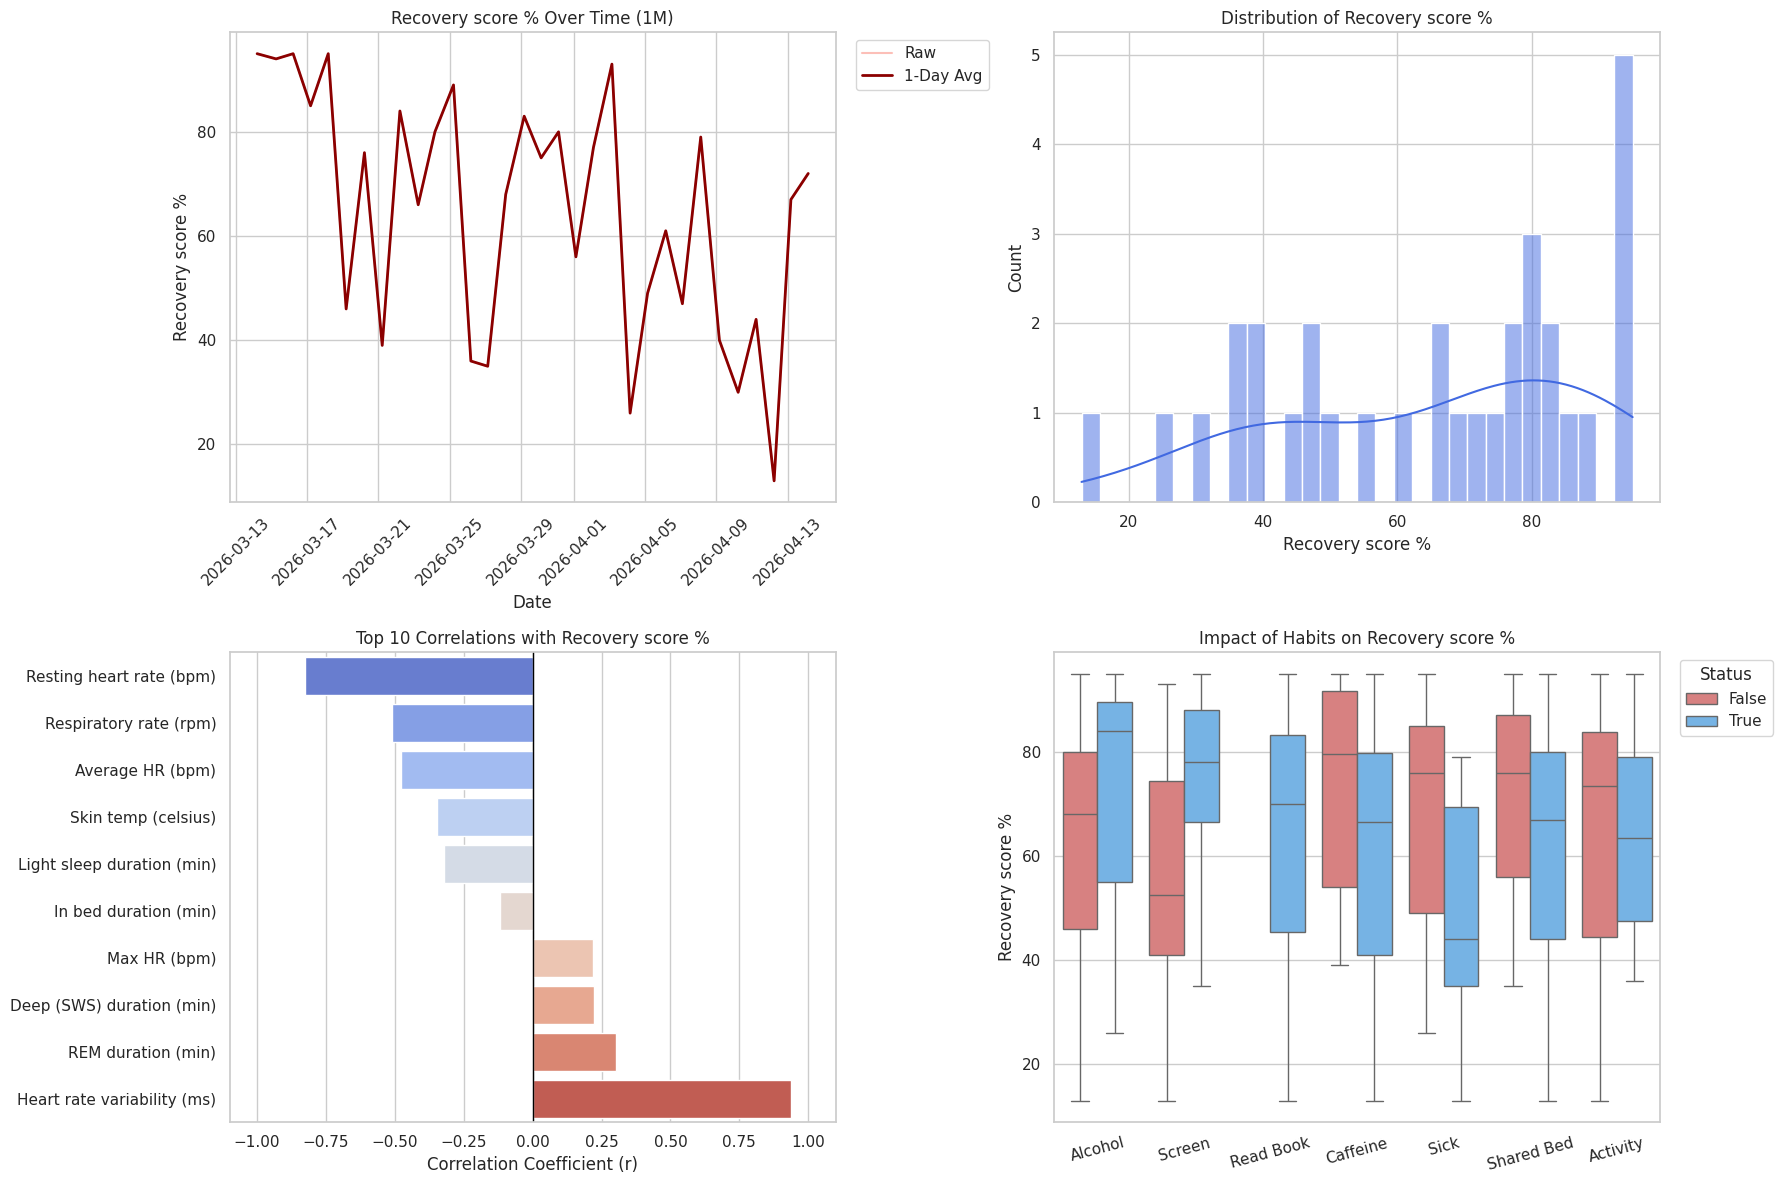

--- Last 3 Months ---


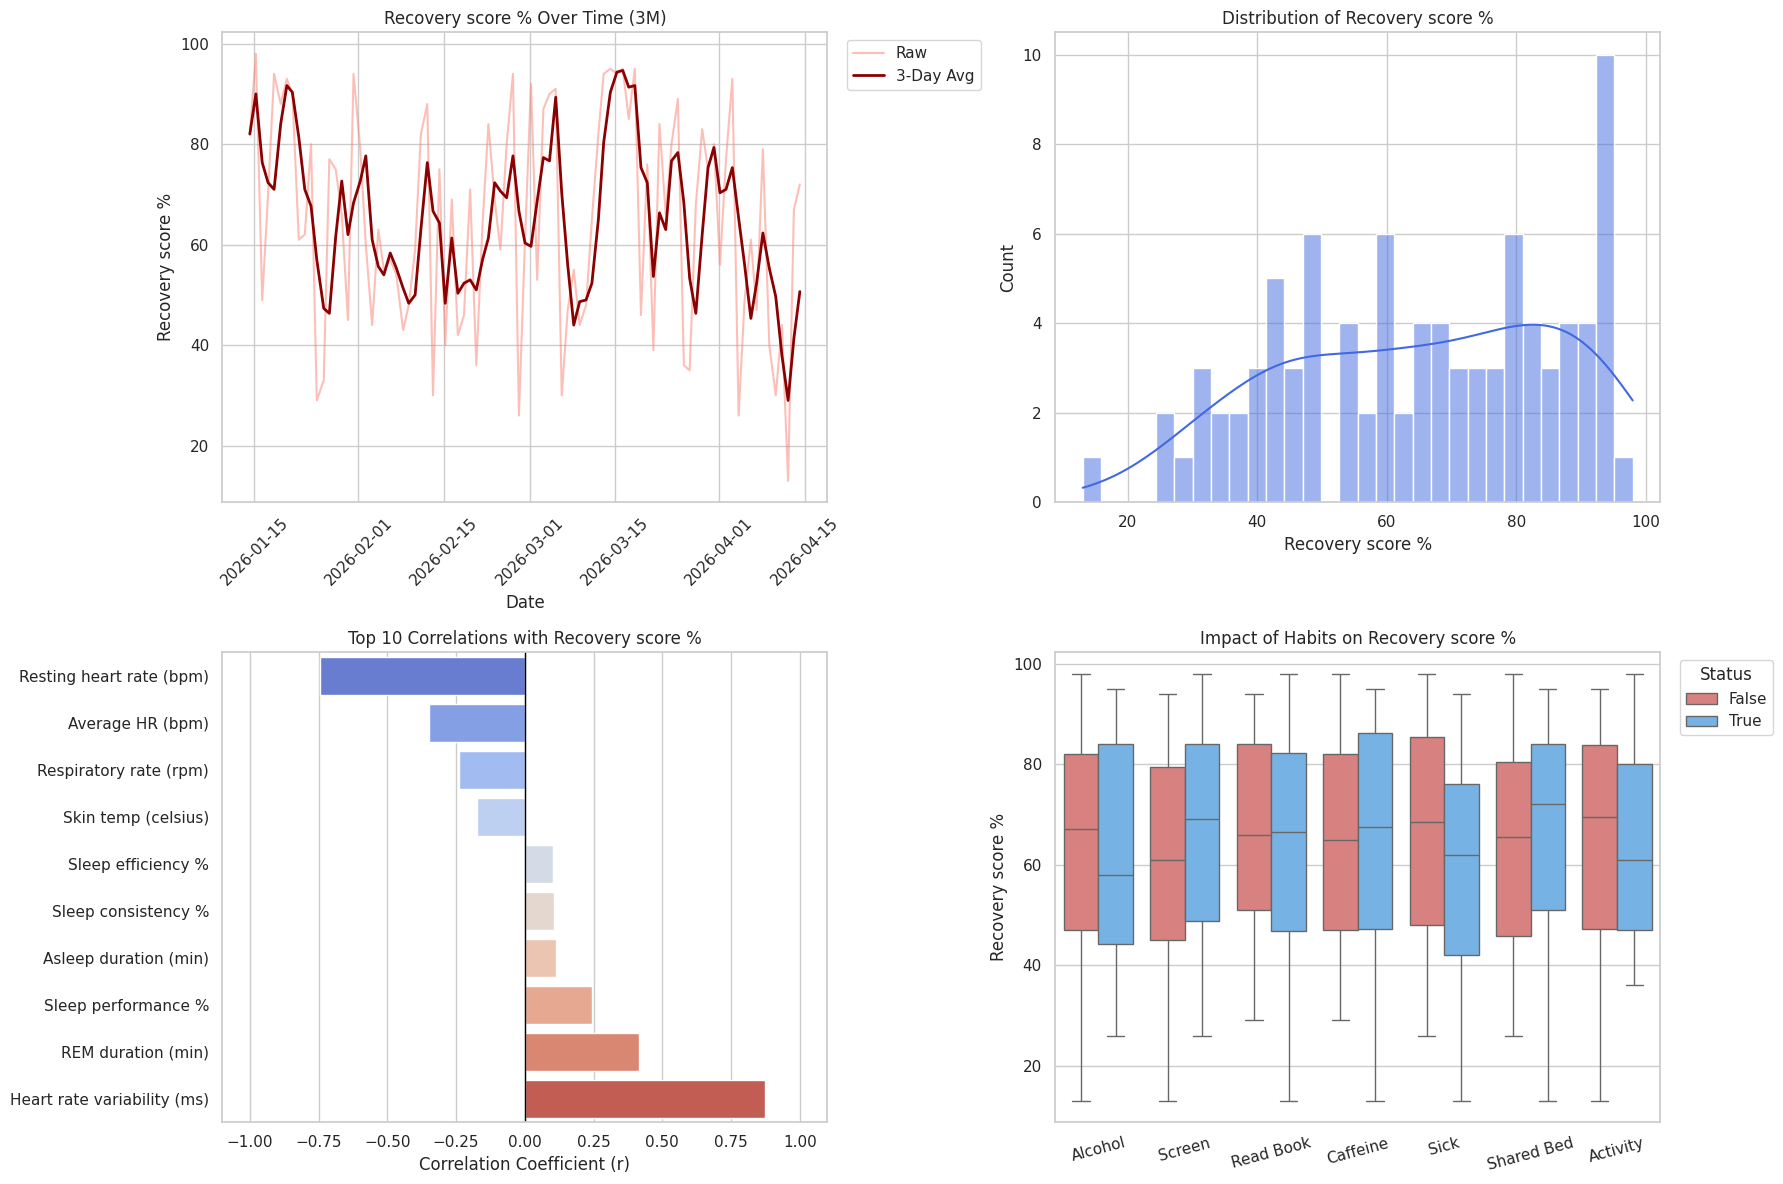

--- Last 6 Months ---


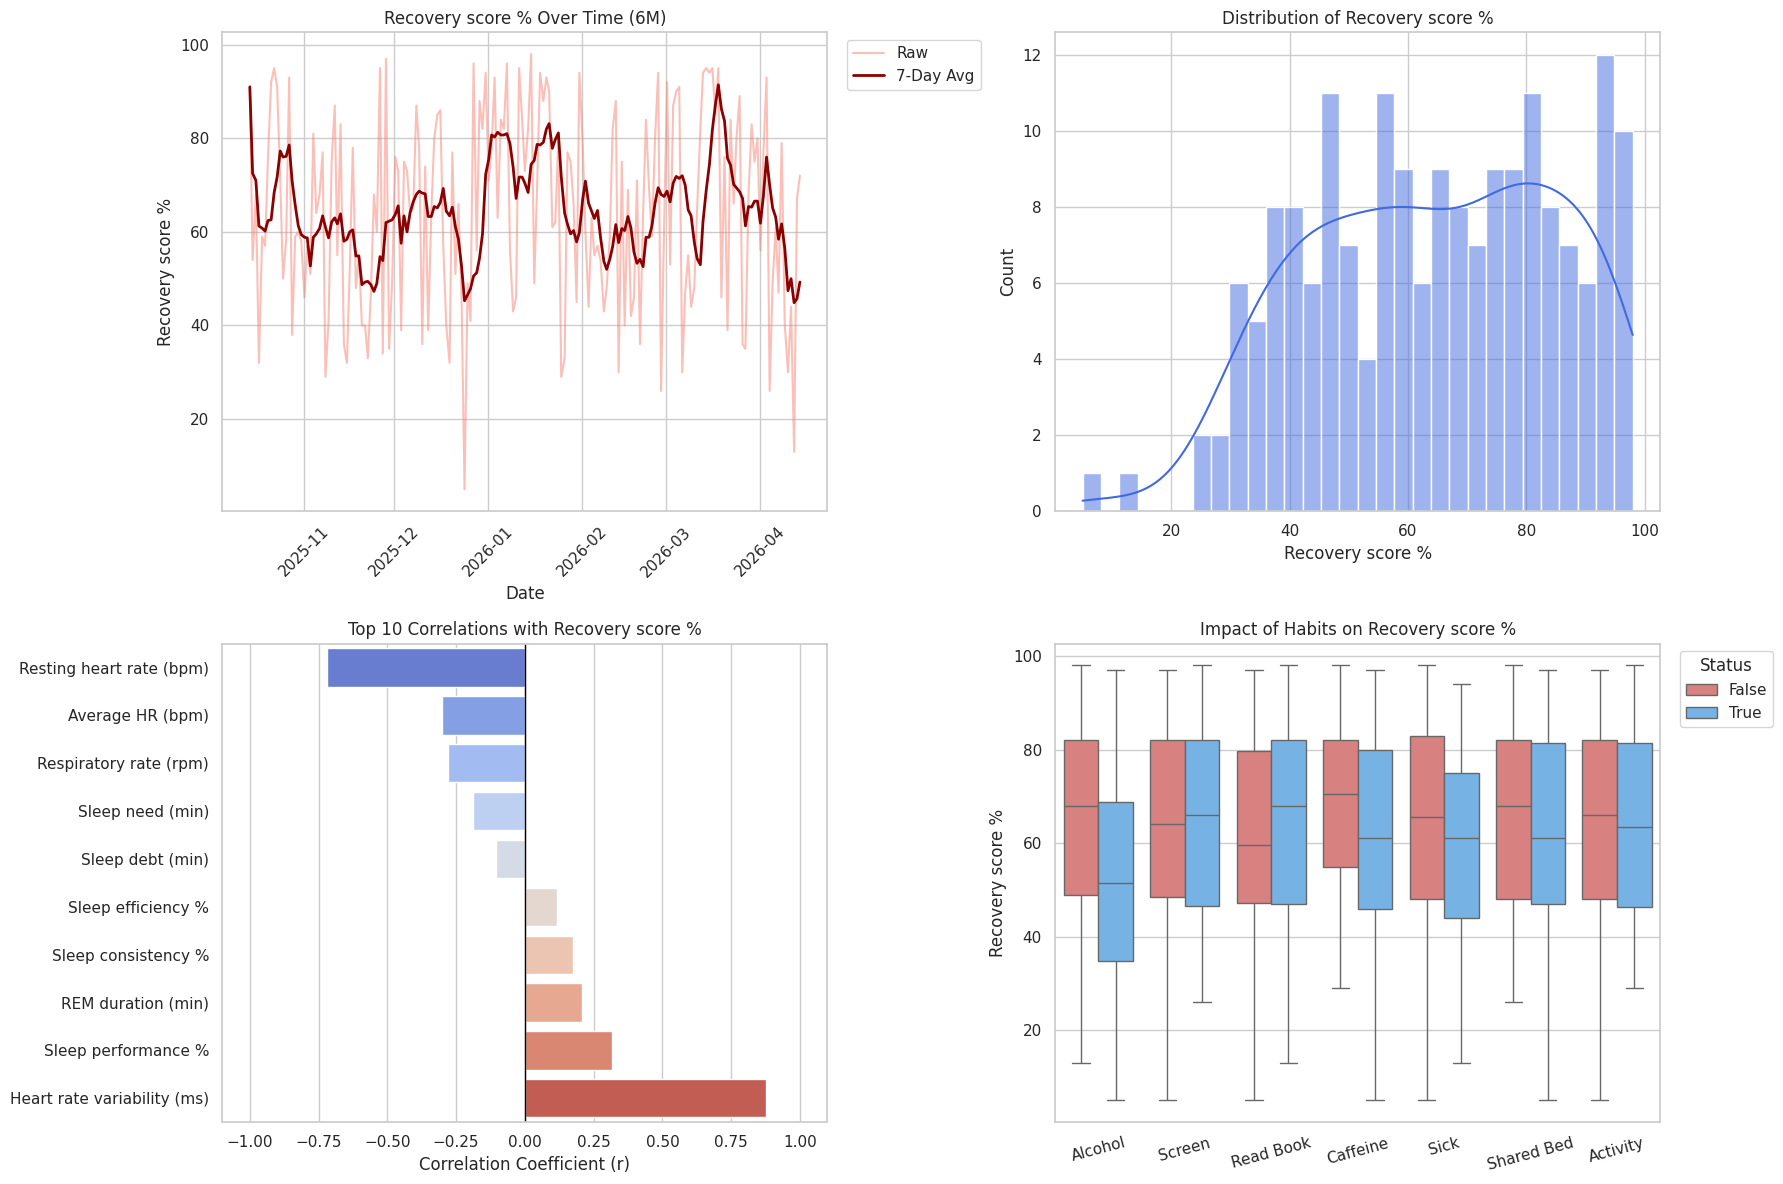

--- Last Year ---


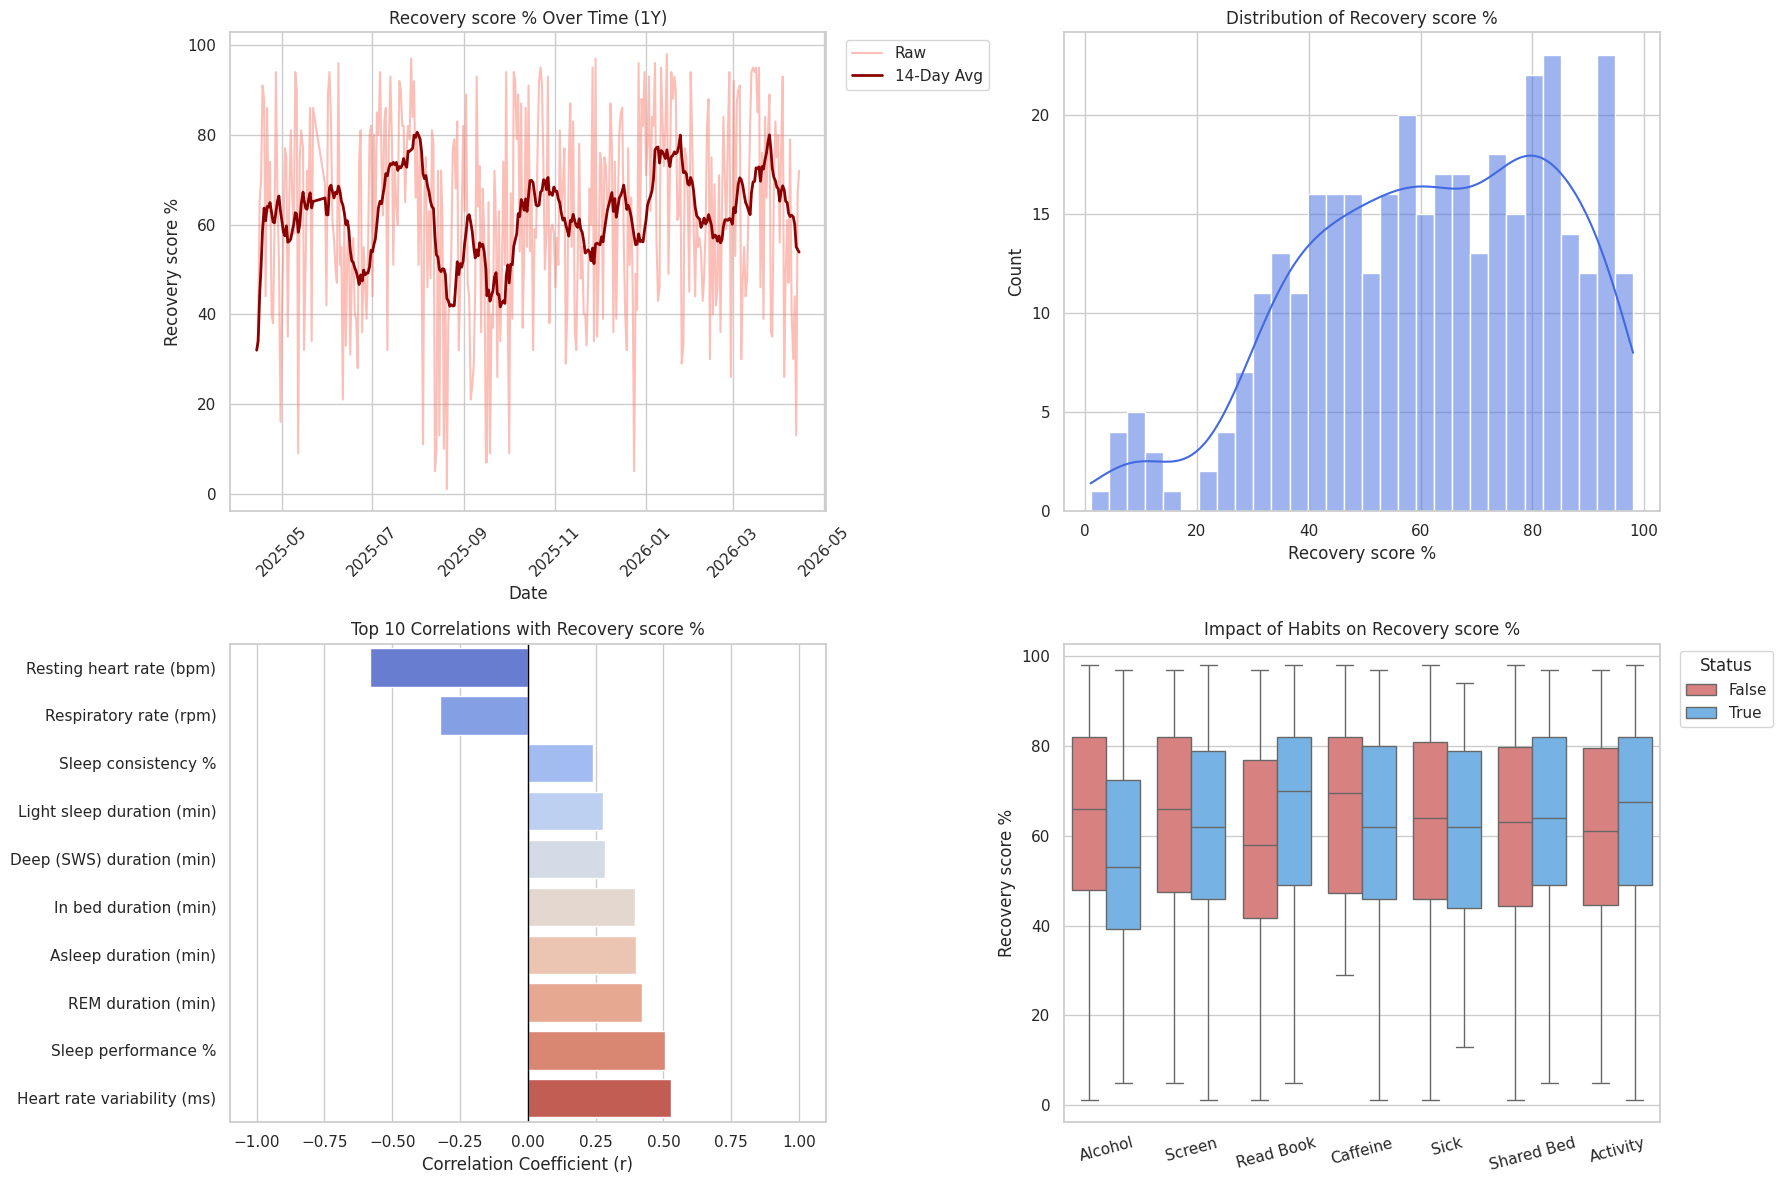

--- Last 2 Years ---


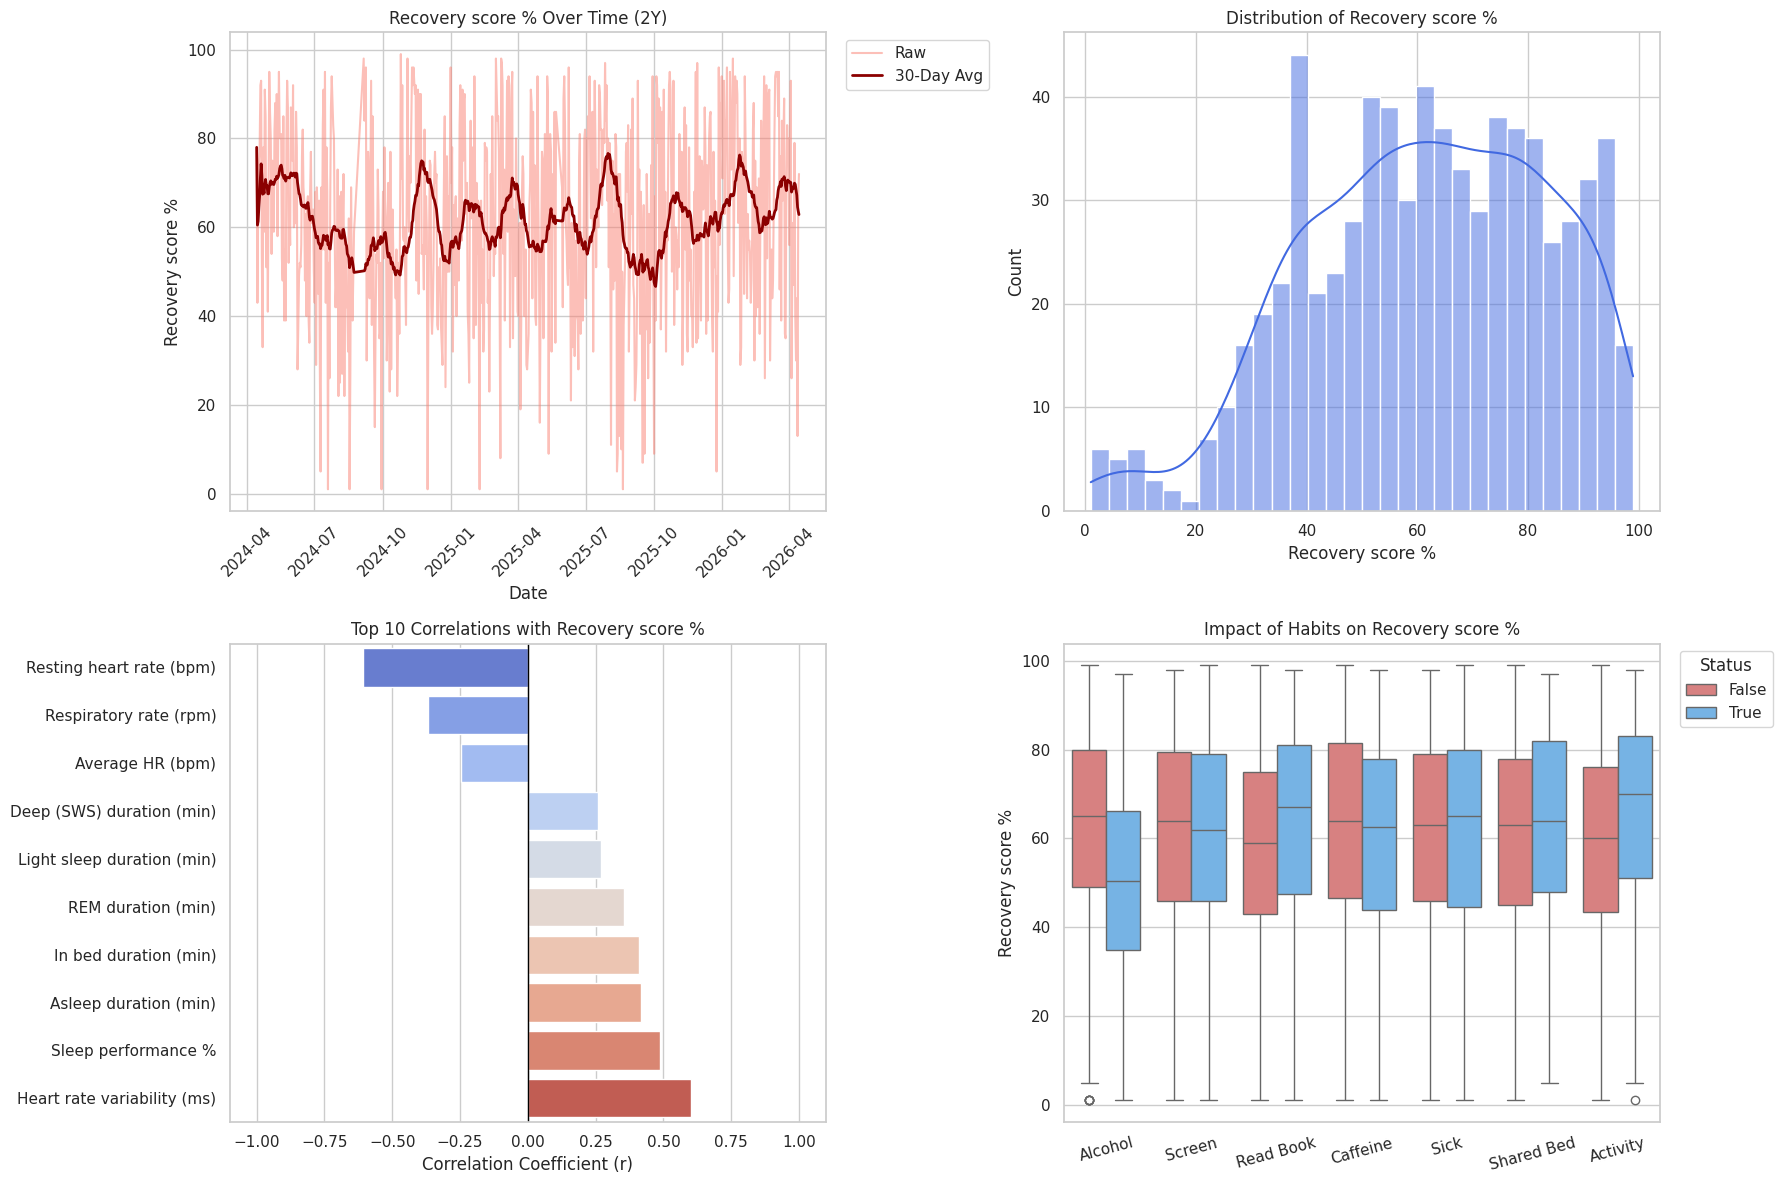

--- All Time ---


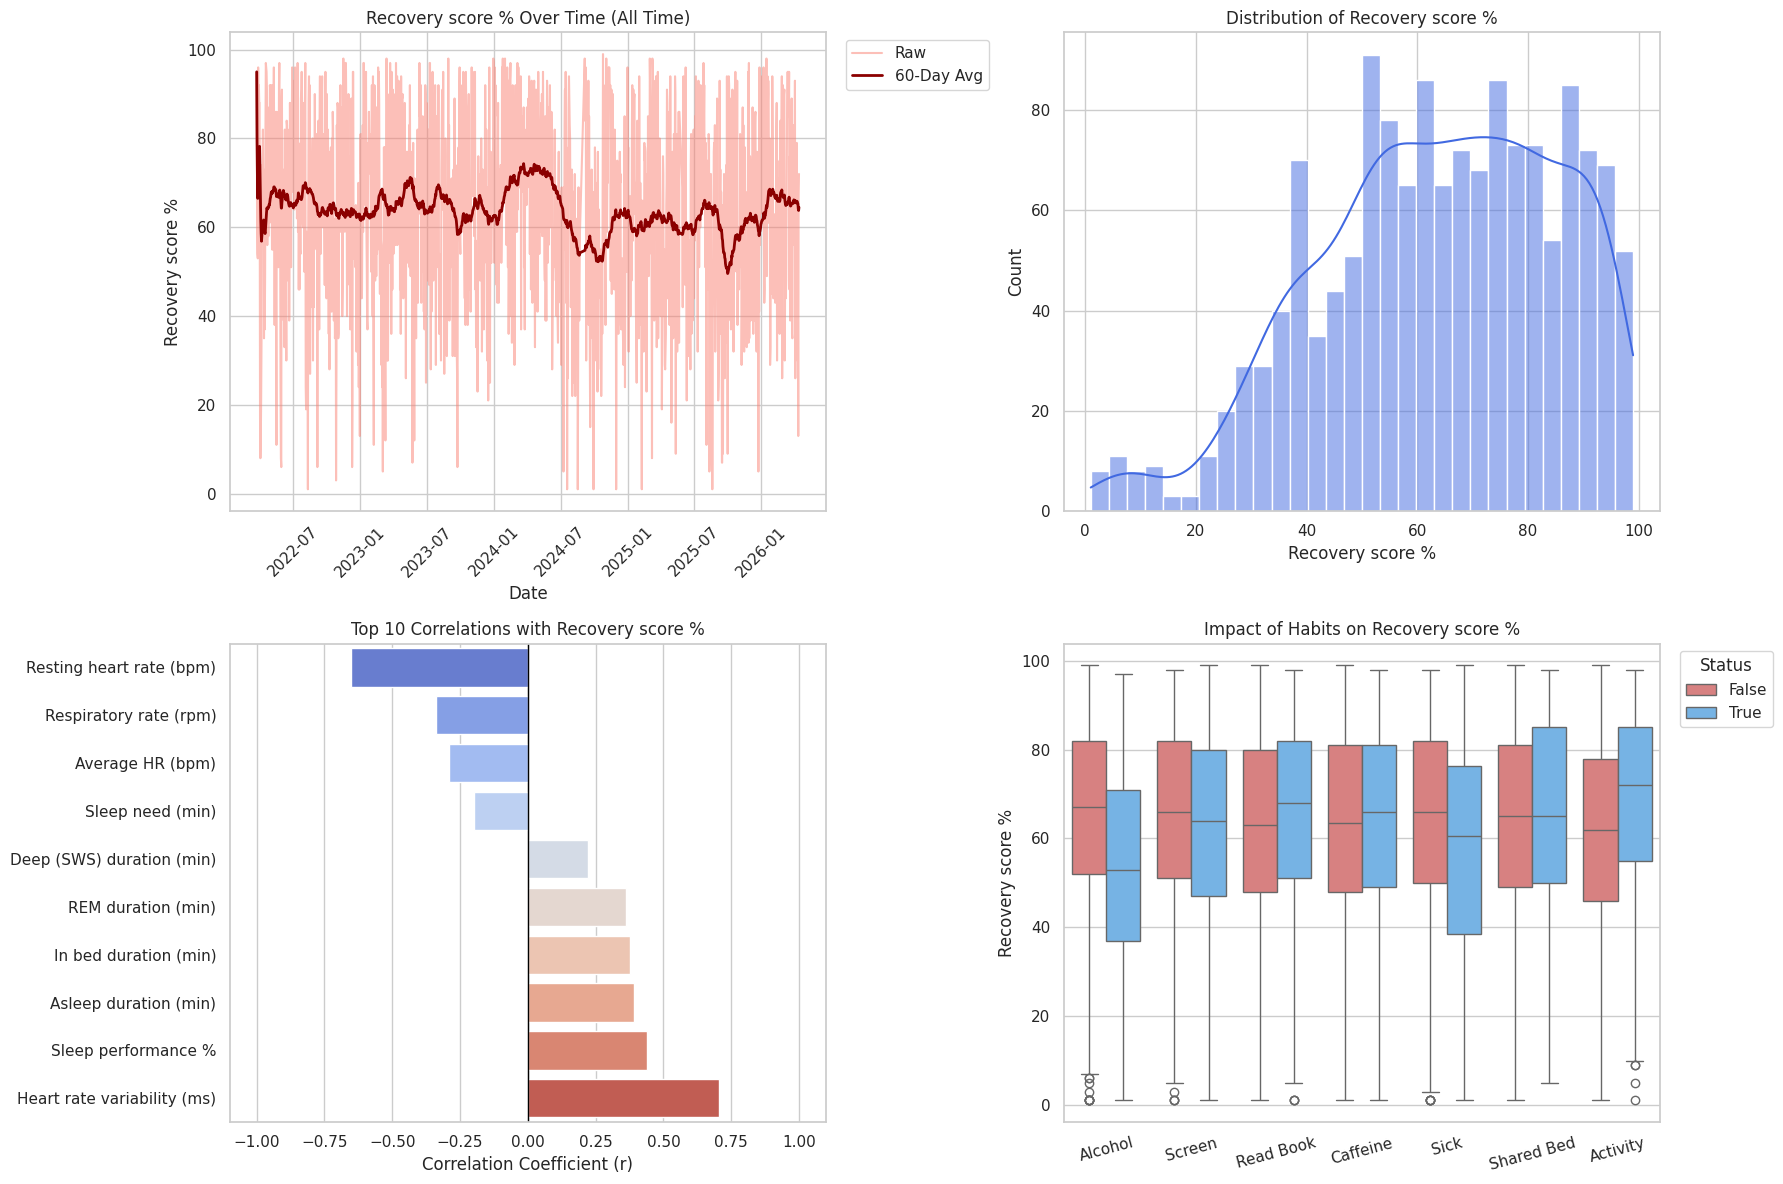

In [7]:
import datetime

def plot_variable_diagnostics(df, col_name, time_window='All Time', top_n_corrs=10):
    """
    Plots a focused diagnostic dashboard for a single variable:
    Time series trend, distribution, top correlations, and habit impact.
    Allows filtering by a specific time window.
    """
    if col_name not in df.columns:
        print(f"Column '{col_name}' not found in dataframe.")
        return

    # Filter data based on time window
    plot_df = df.copy()
    window_size = 60 # Default for All Time
    if 'Cycle start time UTC' in plot_df.columns:
        plot_df['Cycle start time UTC'] = pd.to_datetime(plot_df['Cycle start time UTC'])
        plot_df = plot_df.sort_values('Cycle start time UTC')

        if not plot_df.empty and time_window != 'All Time':
            latest_date = plot_df['Cycle start time UTC'].max()

            if time_window == '1M':
                start_date = latest_date - pd.DateOffset(months=1)
                window_size = 1
            elif time_window == '3M':
                start_date = latest_date - pd.DateOffset(months=3)
                window_size = 3
            elif time_window == '6M':
                start_date = latest_date - pd.DateOffset(months=6)
                window_size = 7
            elif time_window == '1Y':
                start_date = latest_date - pd.DateOffset(years=1)
                window_size = 14
            elif time_window == '2Y':
                start_date = latest_date - pd.DateOffset(years=2)
                window_size = 30
            else:
                start_date = plot_df['Cycle start time UTC'].min()
                window_size = 60

            plot_df = plot_df[plot_df['Cycle start time UTC'] >= start_date]

            if plot_df.empty:
                print(f"No data available for the '{time_window}' window.")
                return

    fig, axes = plt.subplots(2, 2, figsize=(18, 12))
    axes = axes.flatten()

    # Time Series with Smoothing
    sns.lineplot(x='Cycle start time UTC', y=col_name, data=plot_df, ax=axes[0], color='salmon', alpha=0.5, label='Raw')
    # Adjust rolling window dynamically based on data size
    smoothed = plot_df[col_name].rolling(window=window_size, min_periods=1).mean()
    sns.lineplot(x=plot_df['Cycle start time UTC'], y=smoothed, ax=axes[0], color='darkred', linewidth=2, label=f'{window_size}-Day Avg')
    axes[0].set_title(f'{col_name} Over Time ({time_window})')
    axes[0].set_xlabel('Date')
    axes[0].set_ylabel(col_name)
    axes[0].tick_params(axis='x', rotation=45)
    axes[0].legend(loc="upper left", bbox_to_anchor=(1.02, 1))

    # Distribution
    sns.histplot(plot_df[col_name], bins=30, kde=True, ax=axes[1], color='royalblue')
    axes[1].set_title(f'Distribution of {col_name}')
    axes[1].set_xlabel(col_name)
    axes[1].set_ylabel('Count')

    # Top Correlations
    num_cols = plot_df.select_dtypes(include=['number'])
    if col_name in num_cols.columns and len(num_cols.columns) > 1:
        # Calculate correlations, drop the variable itself, and drop NaNs
        corrs = num_cols.corr()[col_name].drop(col_name).dropna()
        # Get top N by absolute value
        top_corrs = corrs.abs().sort_values(ascending=False).head(top_n_corrs).index
        # Get actual correlation values and sort them for the plot
        corr_data = corrs[top_corrs].sort_values()

        sns.barplot(x=corr_data.values, y=corr_data.index, hue=corr_data.index, ax=axes[2], palette='coolwarm', legend=False)
        axes[2].set_title(f'Top {top_n_corrs} Correlations with {col_name}')
        axes[2].set_xlabel('Correlation Coefficient (r)')
        axes[2].set_ylabel('')
        axes[2].set_xlim(-1.1, 1.1)
        axes[2].axvline(0, color='black', linewidth=1)
    else:
        axes[2].text(0.5, 0.5, 'Correlation not available\n(Not a numeric column)',
                     ha='center', va='center', transform=axes[2].transAxes)
        axes[2].set_title(f'Top Correlations with {col_name}')

    # Impact of Habits
    habit_cols = [col for col in ['Alcohol', 'Screen', 'Read Book', 'Caffeine', 'Sick', 'Shared Bed', 'Activity'] if col in plot_df.columns]
    if habit_cols and pd.api.types.is_numeric_dtype(plot_df[col_name]):
        melted = plot_df.melt(id_vars=[col_name], value_vars=habit_cols, var_name='Habit', value_name='Status')
        melted = melted.dropna(subset=['Status'])
        sns.boxplot(data=melted, x='Habit', y=col_name, hue='Status', ax=axes[3], palette=['#e57373', '#64b5f6'])
        axes[3].set_title(f'Impact of Habits on {col_name}')
        axes[3].tick_params(axis='x', rotation=15)
        axes[3].set_xlabel('')

        # Move the legend outside the plot so it doesn't block data
        sns.move_legend(axes[3], "upper left", bbox_to_anchor=(1.02, 1), title='Status')
    else:
        axes[3].text(0.5, 0.5, 'Habit data not available', ha='center', va='center', transform=axes[3].transAxes)
        axes[3].set_title(f'Impact of Habits on {col_name}')

    plt.tight_layout()
    plt.show()

print("--- 1 Month ---")
plot_variable_diagnostics(cycles_df, 'Recovery score %', time_window='1M')

print("--- Last 3 Months ---")
plot_variable_diagnostics(cycles_df, 'Recovery score %', time_window='3M')

print("--- Last 6 Months ---")
plot_variable_diagnostics(cycles_df, 'Recovery score %', time_window='6M')

print("--- Last Year ---")
plot_variable_diagnostics(cycles_df, 'Recovery score %', time_window='1Y')

print("--- Last 2 Years ---")
plot_variable_diagnostics(cycles_df, 'Recovery score %', time_window='2Y')

print("--- All Time ---")
plot_variable_diagnostics(cycles_df, 'Recovery score %', time_window='All Time')


### Predictive Modeling: Forecasting Next-Day Recovery
To predict change in recovery, we frame this as a time-series forecasting problem. We will predict the change in Recovery Score using the current and 3 day lagged physiological metrics and logged habits. We will use Linear Regression and a Random Forest Regressor and split our data chronologically to evaluate its performance fairly.

In [8]:
from sklearn.model_selection import train_test_split
import numpy as np

print("--- Preparing Data for Machine Learning ---")
# Prepare Data for Next-Day Prediction
model_df = cycles_df.copy()
# Ensure chronological order
model_df = model_df.sort_values('Cycle start time UTC').reset_index(drop=True)

# Calculate time between current row and previous row
model_df['Time_Since_Last'] = model_df['Cycle start time UTC'].diff()

# Since we drop anomalous gaps > 16h, any jump larger than ~36 hours (1.5 days) is a distinct break.
gap_threshold = pd.Timedelta(hours=36)

# Create a boolean mask where True means a new segment starts
new_segment_mask = model_df['Time_Since_Last'] > gap_threshold

# Create a unique ID for each continuous segment
model_df['Segment_ID'] = new_segment_mask.cumsum()
print(f"Found {model_df['Segment_ID'].nunique()} continuous segments of data.")
# ---------------------------------

# Feature Engineering: Lagged Features
cols_to_lag = [
    'Recovery score %', 'Heart rate variability (ms)', 'Day Strain',
    'Average HR (bpm)', 'Sleep performance %', 'Sleep consistency %',
    'Respiratory rate (rpm)', 'Alcohol'
]

lag_features = []
for col in cols_to_lag:
    if col in model_df.columns:
        for lag in [1, 2, 3]:
            new_col_name = f'{col}_lag{lag}'
            # Shift within each segment
            model_df[new_col_name] = model_df.groupby('Segment_ID')[col].shift(lag)
            lag_features.append(new_col_name)

# Change in Recovery Score (Tomorrow - Today)
# Shifted within the segment to avoid predicting across a gap
model_df['Target_Recovery_Change'] = model_df.groupby('Segment_ID')['Recovery score %'].shift(-1) - model_df['Recovery score %']

# Drop rows with NaNs introduced by the shifts
model_df = model_df.dropna(subset=['Target_Recovery_Change'] + lag_features).reset_index(drop=True)

# Define features
base_features = [
  'Recovery score %', 'Heart rate variability (ms)', 'Day Strain',
  'Average HR (bpm)', 'Sleep performance %', 'Sleep consistency %',
  'Respiratory rate (rpm)', 'Asleep duration (min)'
]
features = [f for f in base_features + lag_features if f in model_df.columns]

X = model_df[features].astype(float)
y = model_df['Target_Recovery_Change']

# Chronological Train/Test Split 80/20
split_idx = int(len(model_df) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

print(f"Training on {len(X_train)} days, Testing on {len(X_test)} days.")
print(f"Total features used: {len(features)}")


--- Preparing Data for Machine Learning ---
Found 6 continuous segments of data.
Training on 1148 days, Testing on 288 days.
Total features used: 32


### Model Training and Evaluation
Training Random Forest, Linear Regression, and establishing naive baselines for comparison.

In [9]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("--- Training and Evaluating Models ---")

# Normalize data for Linear Regression
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Initialize Models
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, max_depth=10)
lr_model = LinearRegression()

# Train Models
rf_model.fit(X_train, y_train)
lr_model.fit(X_train_scaled, y_train)

# Generate Predictions
y_pred = rf_model.predict(X_test)
y_pred_lr = lr_model.predict(X_test_scaled)
zero_pred = np.zeros_like(y_test)

predictions = {
    'Random Forest': y_pred,
    'Linear Regression (Normalized)': y_pred_lr,
    'Baseline: Predict Zero Change': zero_pred
}

# Evaluate and Compare
results = []
for name, preds in predictions.items():
    mae = mean_absolute_error(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    r2 = r2_score(y_test, preds)
    results.append({'Model': name, 'MAE': mae, 'RMSE': rmse, 'R2': r2})

results_df = pd.DataFrame(results).sort_values('MAE').reset_index(drop=True)
display(results_df.round(3))


--- Training and Evaluating Models ---


,Model,MAE,RMSE,R2
0,Linear Regression (Normalized),16.763,20.949,0.456
1,Random Forest,17.125,21.082,0.449
2,Baseline: Predict Zero Change,22.799,28.407,-0.000


### Model Prediction Dashboard
Let's consolidate our evaluation into a clean dashboard function.

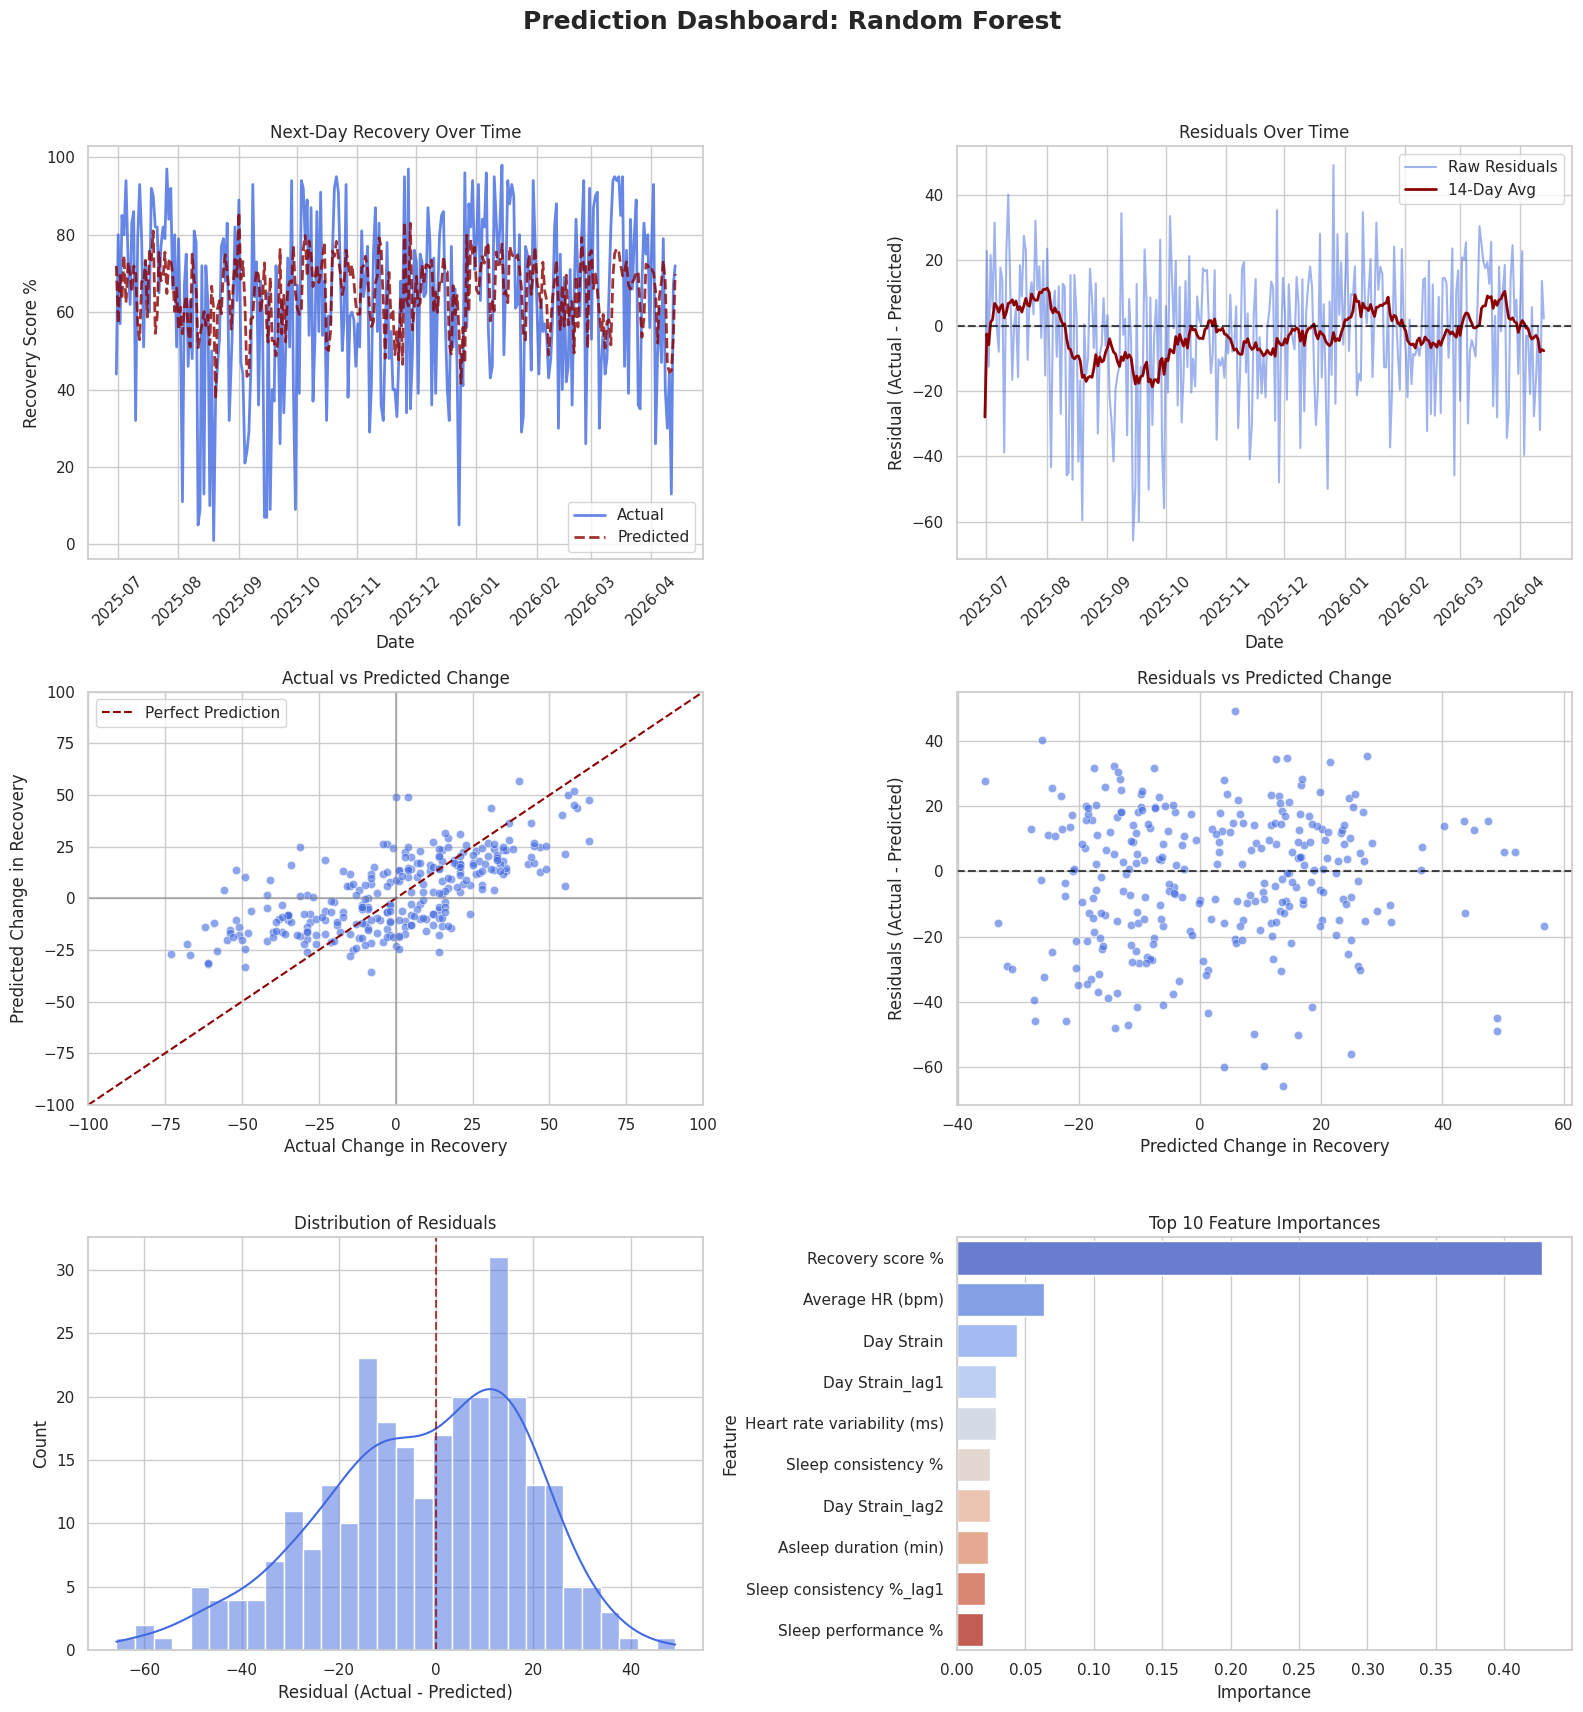

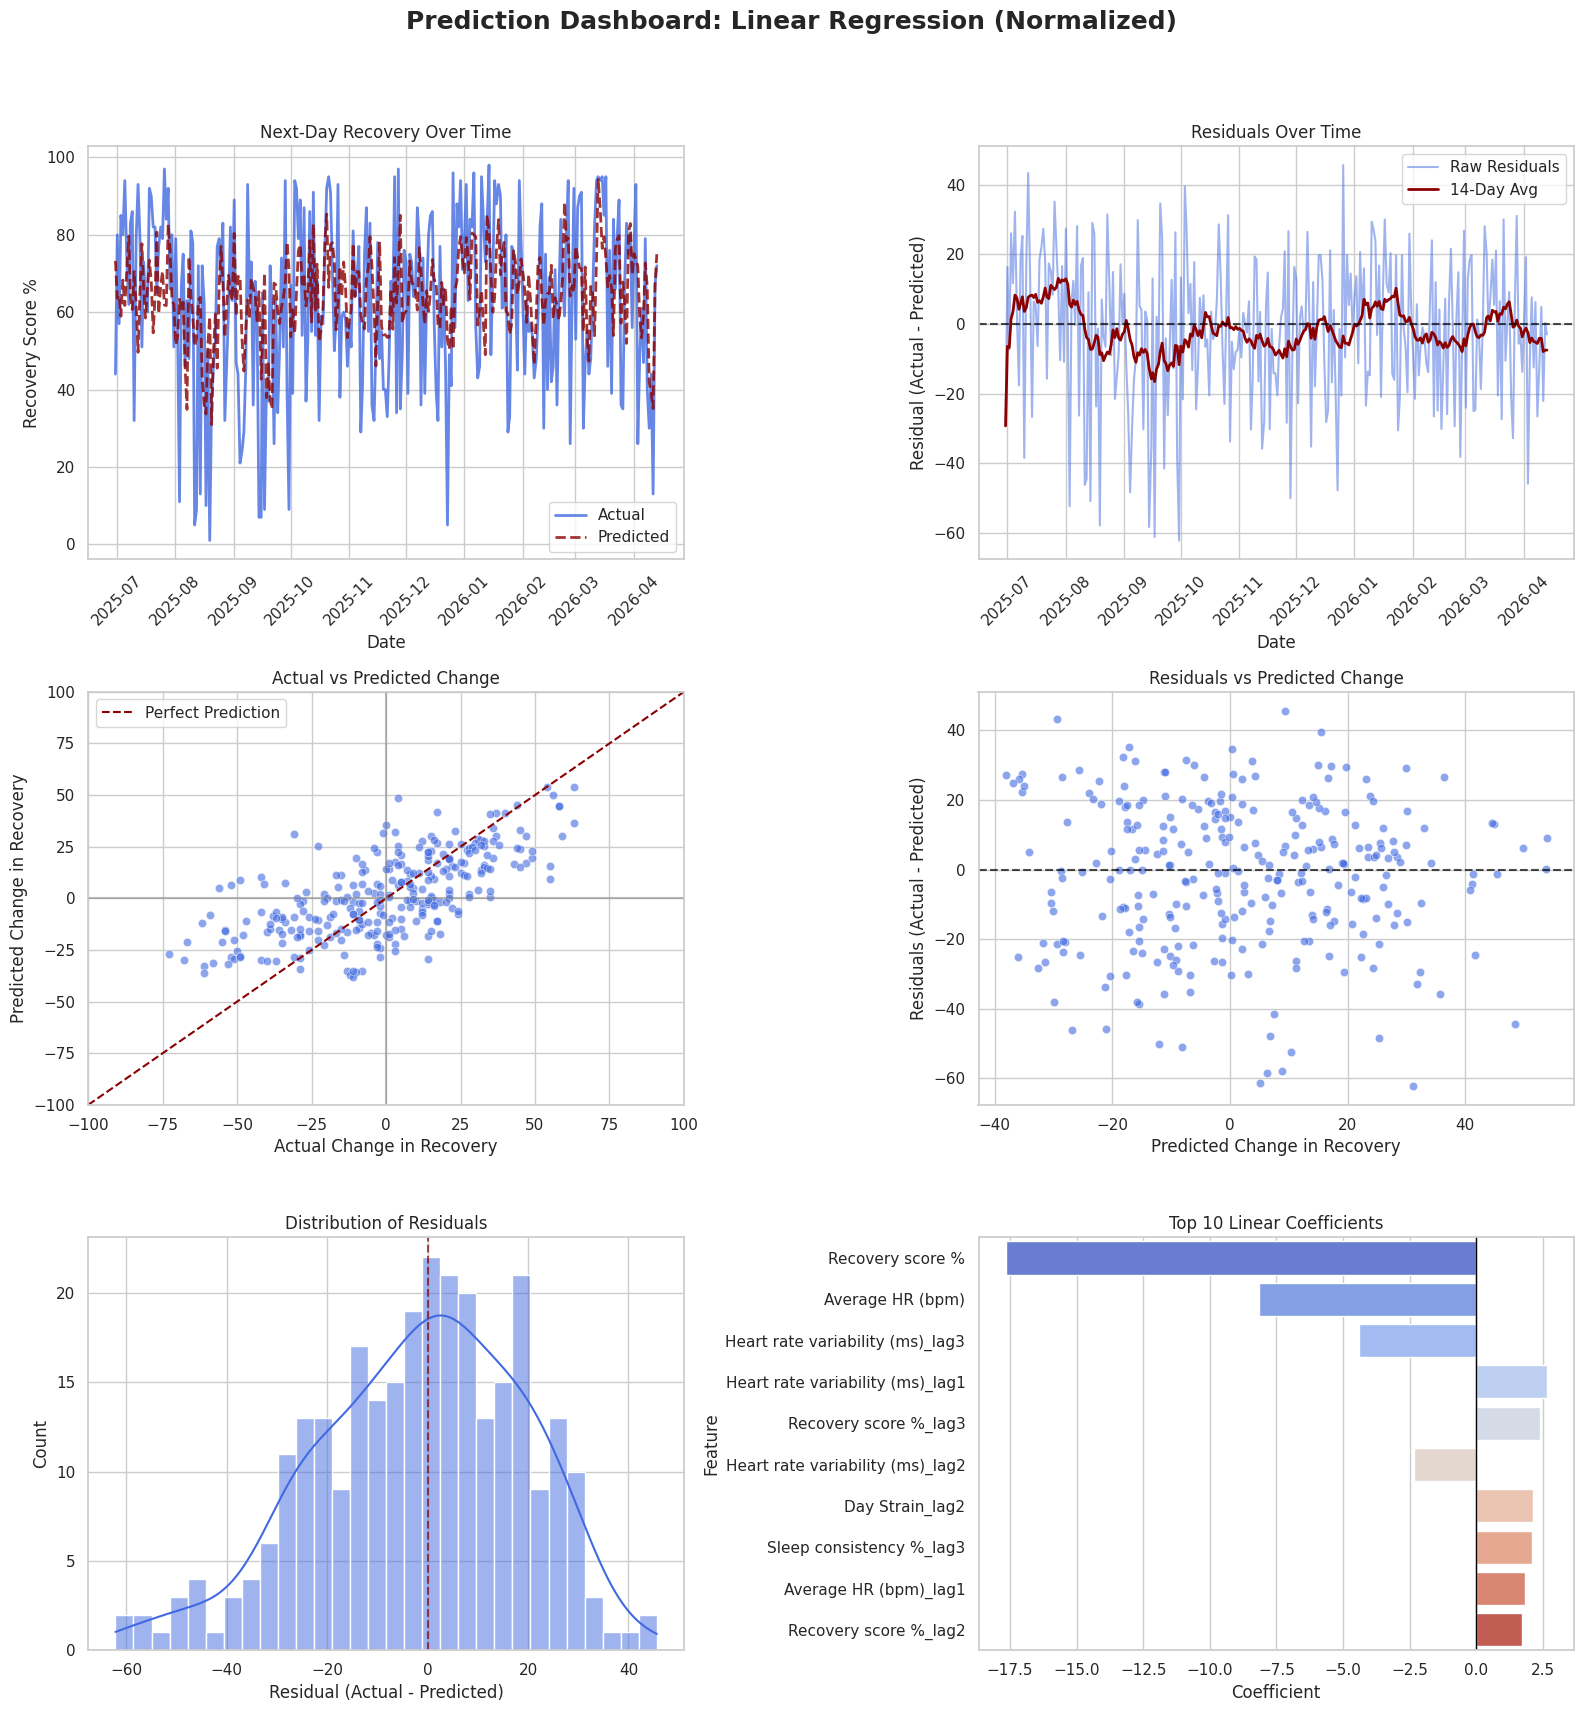

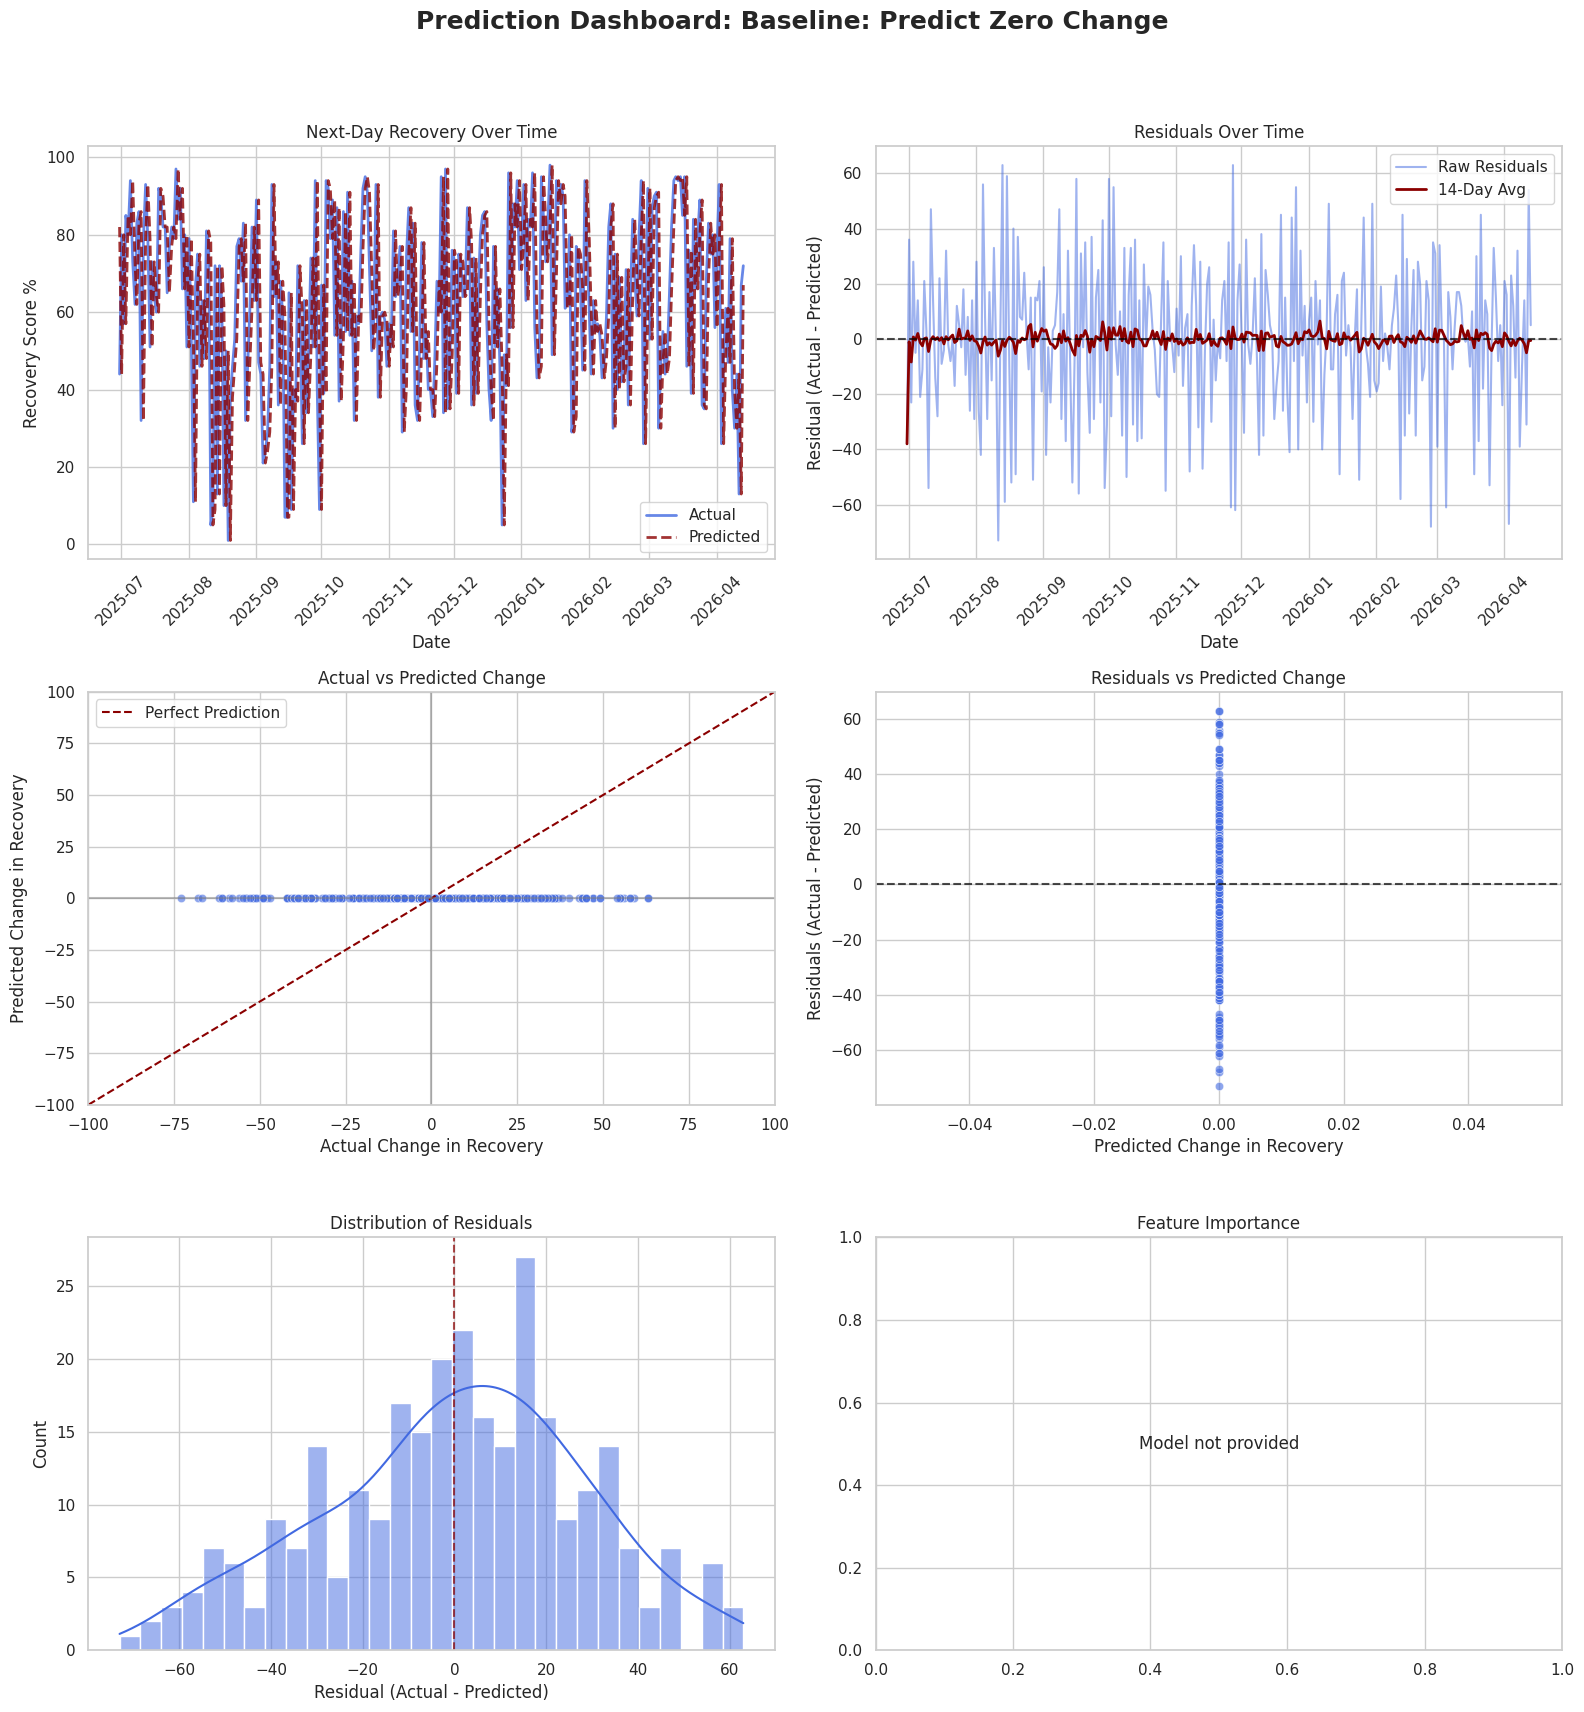

In [10]:
def plot_model_diagnostics(y_true, y_pred, today_recovery, dates, model_name, model=None, feature_names=None):
    """
    Plots a 3x2 diagnostic dashboard for a recovery prediction model.
    """
    # Calculate absolute next day recoveries
    actual_next_day = (today_recovery + y_true).clip(1, 100)
    pred_next_day = (today_recovery + y_pred).clip(1, 100)

    # Calculate residuals
    residuals = y_true - y_pred

    fig, axes = plt.subplots(3, 2, figsize=(16, 18))
    fig.suptitle(f'Prediction Dashboard: {model_name}', fontsize=18, weight='bold')

    # Actual vs Predicted Next-Day Recovery (Time Series)
    plot_df = pd.DataFrame({'Date': dates, 'Actual': actual_next_day, 'Predicted': pred_next_day})
    plot_df = plot_df.sort_values('Date')
    sns.lineplot(data=plot_df, x='Date', y='Actual', ax=axes[0,0], color='royalblue', label='Actual', alpha=0.8, linewidth=2)
    sns.lineplot(data=plot_df, x='Date', y='Predicted', ax=axes[0,0], color='darkred', label='Predicted', linestyle='--', alpha=0.8, linewidth=2)
    axes[0,0].set_title('Next-Day Recovery Over Time')
    axes[0,0].set_ylabel('Recovery Score %')
    axes[0,0].tick_params(axis='x', rotation=45)

    # Residuals Over Time
    ax_res_time = axes[0, 1]
    res_df = pd.DataFrame({'Date': dates, 'Residuals': residuals}).sort_values('Date')

    # Add a 14-day rolling average for the smoothed line
    smoothed_res = res_df['Residuals'].rolling(window=14, min_periods=1).mean()

    sns.lineplot(data=res_df, x='Date', y='Residuals', ax=ax_res_time, alpha=0.5, color='royalblue', label='Raw Residuals')
    sns.lineplot(x=res_df['Date'], y=smoothed_res, ax=ax_res_time, color='darkred', linewidth=2, label='14-Day Avg')

    ax_res_time.axhline(0, color='black', linestyle='--', alpha=0.7)
    ax_res_time.set_title('Residuals Over Time')
    ax_res_time.set_xlabel('Date')
    ax_res_time.set_ylabel('Residual (Actual - Predicted)')
    ax_res_time.tick_params(axis='x', rotation=45)
    ax_res_time.legend()

    # Actual vs Predicted Change (Scatter)
    sns.scatterplot(x=y_true, y=y_pred, ax=axes[1,0], alpha=0.6, color='royalblue')
    axes[1,0].plot([-100, 100], [-100, 100], color='darkred', linestyle='--', label='Perfect Prediction')
    axes[1,0].axhline(0, color='grey', linestyle='-', alpha=0.5)
    axes[1,0].axvline(0, color='grey', linestyle='-', alpha=0.5)
    axes[1,0].set_title('Actual vs Predicted Change')
    axes[1,0].set_xlabel('Actual Change in Recovery')
    axes[1,0].set_ylabel('Predicted Change in Recovery')
    axes[1,0].set_xlim(-100, 100)
    axes[1,0].set_ylim(-100, 100)
    axes[1,0].legend()

    # Residuals vs Predicted
    sns.scatterplot(x=y_pred, y=residuals, ax=axes[1,1], alpha=0.6, color='royalblue')
    axes[1,1].axhline(0, color='black', linestyle='--', alpha=0.7)
    axes[1,1].set_title('Residuals vs Predicted Change')
    axes[1,1].set_xlabel('Predicted Change in Recovery')
    axes[1,1].set_ylabel('Residuals (Actual - Predicted)')

    # Residual Distribution
    sns.histplot(residuals, bins=30, kde=True, ax=axes[2,0], color='royalblue')
    axes[2,0].axvline(0, color='darkred', linestyle='--', alpha=0.7)
    axes[2,0].set_title('Distribution of Residuals')
    axes[2,0].set_xlabel('Residual (Actual - Predicted)')

    # Feature Importance
    ax_imp = axes[2, 1]

    if model is not None and feature_names is not None:
        if hasattr(model, 'feature_importances_'):
            importances = model.feature_importances_
            imp_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
            imp_df = imp_df.sort_values('Importance', ascending=False).head(10)
            sns.barplot(x='Importance', y='Feature', data=imp_df, ax=ax_imp, palette='coolwarm', hue='Feature', legend=False)
            ax_imp.set_title('Top 10 Feature Importances')
        elif hasattr(model, 'coef_'):
            coefs = model.coef_
            if coefs.ndim > 1:
                coefs = coefs[0]
            imp_df = pd.DataFrame({'Feature': feature_names, 'Coefficient': coefs})
            imp_df['Abs_Coef'] = imp_df['Coefficient'].abs()
            imp_df = imp_df.sort_values('Abs_Coef', ascending=False).head(10)
            sns.barplot(x='Coefficient', y='Feature', data=imp_df, ax=ax_imp, palette='coolwarm', hue='Feature', legend=False)
            ax_imp.axvline(0, color='black', linewidth=1)
            ax_imp.set_title('Top 10 Linear Coefficients')
        else:
            ax_imp.text(0.5, 0.5, 'No feature importance available', ha='center', va='center')
            ax_imp.set_title('Feature Importance')
    else:
        ax_imp.text(0.5, 0.5, 'Model not provided', ha='center', va='center')
        ax_imp.set_title('Feature Importance')

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()


# Extract base series
dates = model_df.loc[y_test.index, 'Cycle start time UTC']
today_rec = X_test['Recovery score %']

# Dictionary of models and their predictions
models_to_evaluate = {
    'Random Forest': (y_pred, rf_model),
    'Linear Regression (Normalized)': (y_pred_lr, lr_model),
    'Baseline: Predict Zero Change': (zero_pred, None)
}

# Loop through and plot
for name, (predictions, model) in models_to_evaluate.items():
    plot_model_diagnostics(y_test, predictions, today_rec, dates, name, model=model, feature_names=X.columns)


### Training Data Diagnostics
Let's run the same diagnostic dashboards on the **training data**.

--- Generating Dashboards for Training Data ---


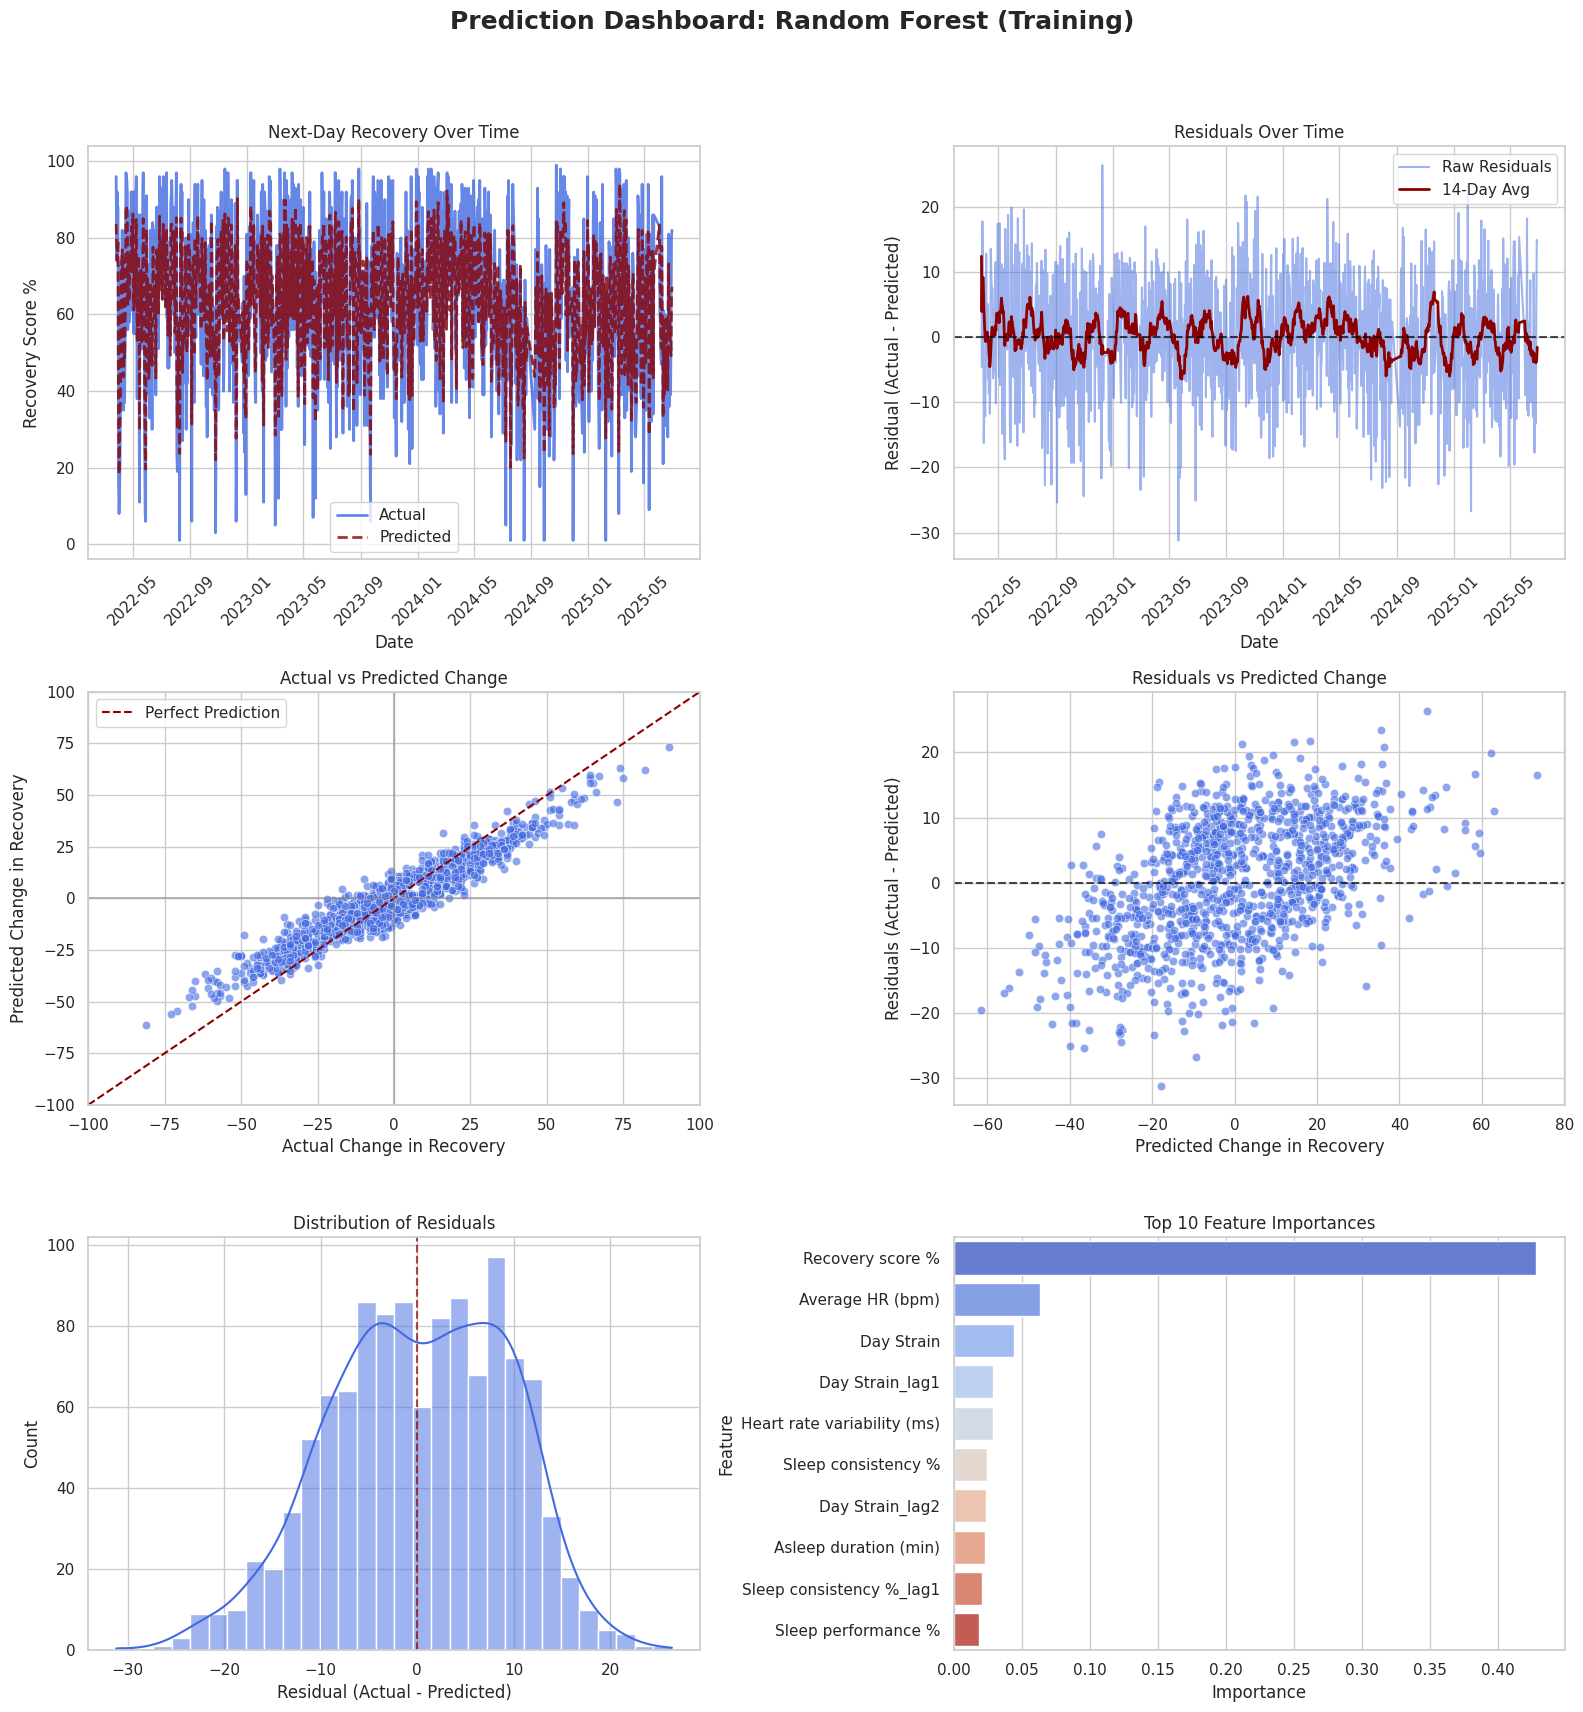

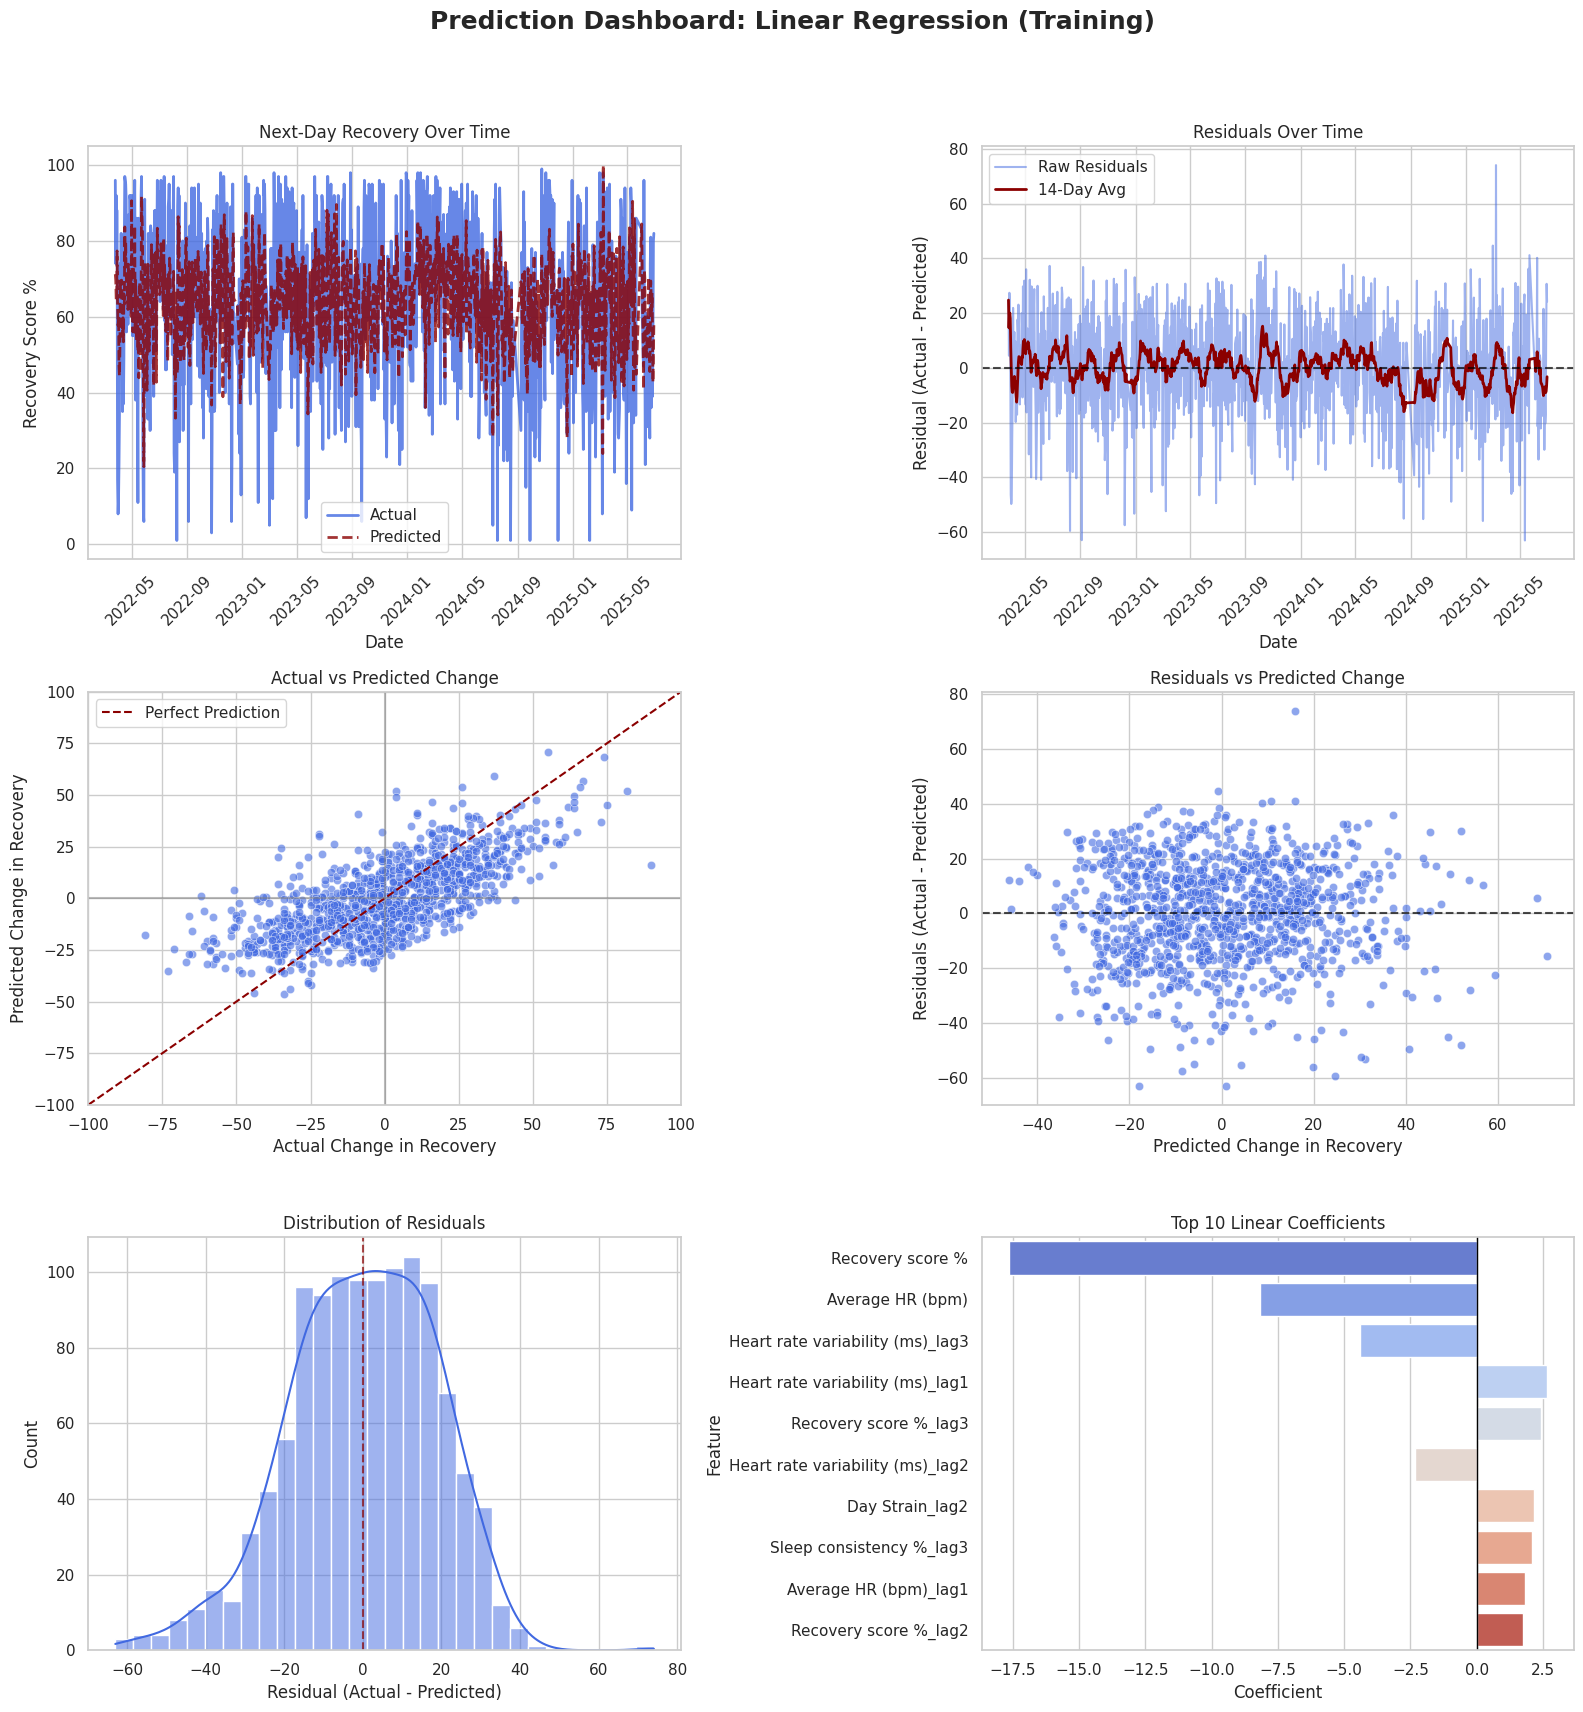

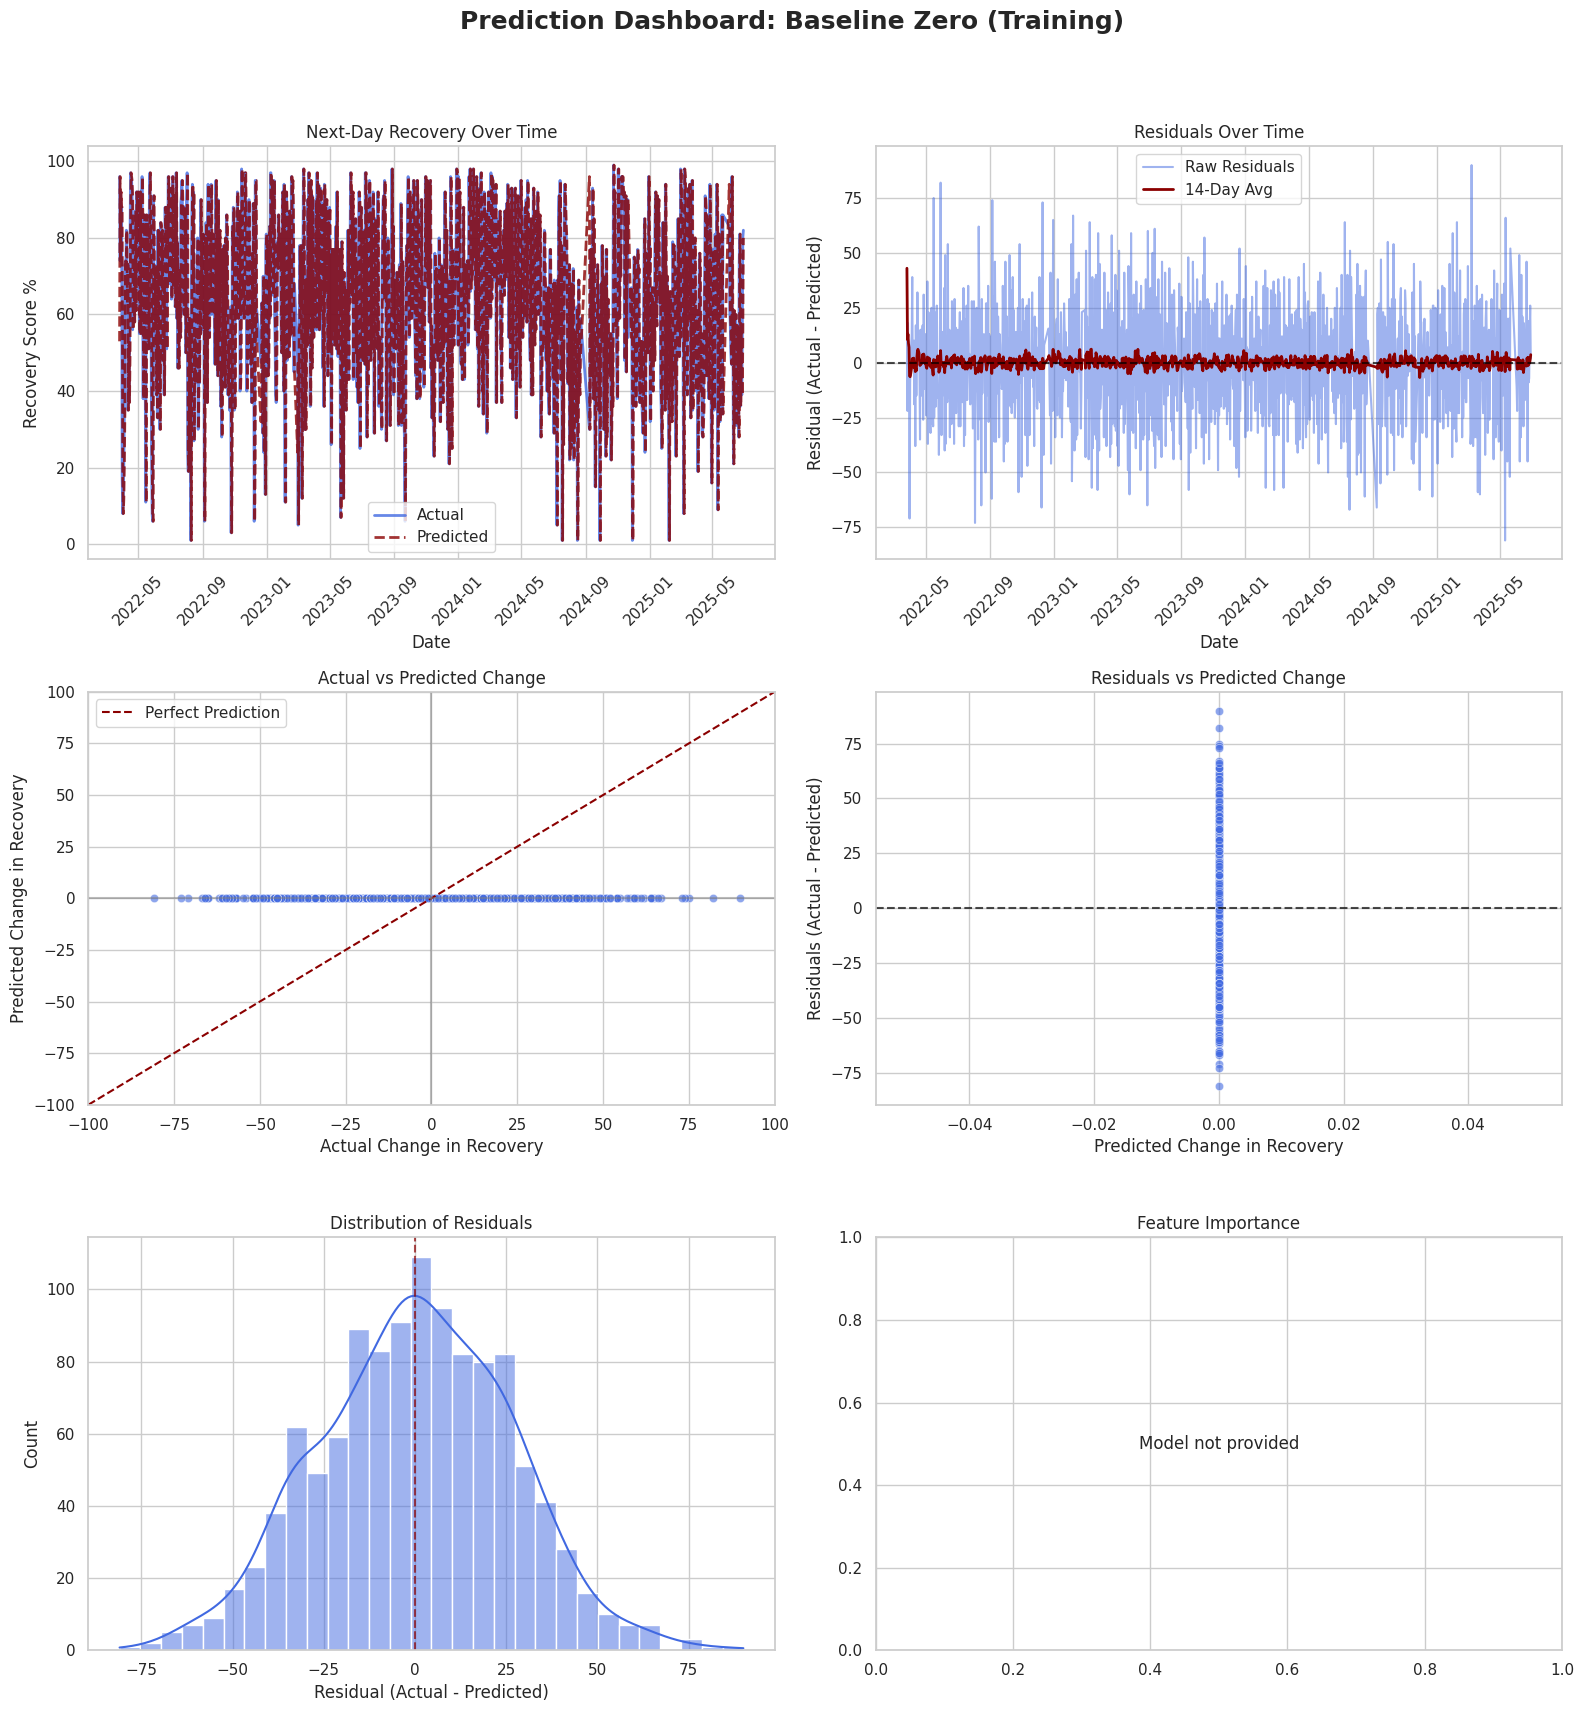

In [11]:
# Generate predictions for the training set
y_train_pred_rf = rf_model.predict(X_train)
y_train_pred_lr = lr_model.predict(X_train_scaled)
zero_pred_train = np.zeros_like(y_train)

# Extract base series for the training set
dates_train = model_df.loc[y_train.index, 'Cycle start time UTC']
today_rec_train = X_train['Recovery score %']

# Dictionary of models and their training predictions
models_to_evaluate_train = {
    'Random Forest (Training)': (y_train_pred_rf, rf_model),
    'Linear Regression (Training)': (y_train_pred_lr, lr_model),
    'Baseline Zero (Training)': (zero_pred_train, None)
}

print("--- Generating Dashboards for Training Data ---")
# Loop through and plot
for name, (predictions, model) in models_to_evaluate_train.items():
    plot_model_diagnostics(y_train, predictions, today_rec_train, dates_train, name, model=model, feature_names=X.columns)
